# Stock Price Prediction - ML Minor Project

Stock Price Prediction - ML Minor Project | Corizo Machine Learning October'26 (Live Edge) | Name: Dhaksith Subramanian

### One-step-ahead forecasting of **RELIANCE.NS** using classical ML and an LSTM

**Problem statement.** Given the daily OHLCV history of a single stock, predict the closing price of the
*next* trading day. This is supervised regression on a time series: a feature row built at the close of day
`t` may only use information that was available at that moment, and its label is the close of day `t + 1`.

**Why it is non-trivial.** Daily equity prices are close to a random walk. A model that merely repeats
today's close is a surprisingly strong benchmark, so every model below is compared against that naive
forecast on exactly the same test period. Beating it on RMSE is the first bar; adding value also requires
useful directional accuracy (better than a coin flip).

**Dataset.** Eight years of daily data downloaded with `yfinance` (default `RELIANCE.NS`, fallback `AAPL`),
stored at `data/stock.csv`. All prices are in INR.

**Pipeline.**

| Step | What happens |
|---|---|
| 1. Problem & data | Load, audit shape, date range, dtypes, missing values |
| 2. EDA | Price, volume, moving averages, return distribution, correlations |
| 3. Features | Lags, SMAs, RSI, MACD, Bollinger width, volatility, returns → next-day close |
| 4. Split | Chronological 80/20 split, scaler fitted on train only |
| 5. Models | Naive, Linear Regression, Random Forest, XGBoost, LSTM (60-day window) |
| 6. Evaluation | RMSE, MAE, MAPE, R², directional accuracy + comparison chart |
| 7. Diagnostics | Actual vs predicted, residuals, tree feature importance |
| 8. Return & direction | Return-target models and UP/DOWN classifiers |
| 9. Deployment | Persist the best fitted model and score tomorrow's close with `predict_next_day()` |
| 10. Conclusion | Honest verdict, limitations and future work |

> **Disclaimer.** This is a project for the Corizo Machine Learning program, not investment advice. Past performance does not guarantee
> future results, and a next-day point forecast ignores transaction costs, slippage and risk.

## 1. Problem statement and dataset

We forecast the **next trading day's close** from technical indicators derived only from past prices and
volume. The table below documents the raw file; the audit checks shape, date coverage, gaps, duplicates
and missing values before anything is modelled.

| Column | Meaning |
|---|---|
| `Date` | Trading date (Yahoo Finance calendar) |
| `Open`, `High`, `Low`, `Close` | Daily OHLC prices in INR (split-adjusted by Yahoo) |
| `Adj Close` | Close adjusted for dividends and splits |
| `Volume` | Shares traded |

`Close` is the modelling target; `Adj Close` is kept for reference. Yahoo already back-adjusts the OHLC
series for splits, so there is no artificial price jump from corporate actions in the modelling window.

In [1]:
# ---------------------------------------------------------------------------
# Imports, configuration and reproducibility
# ---------------------------------------------------------------------------
import json
import os
import random
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from ta.momentum import RSIIndicator
from ta.trend import MACD
from ta.volatility import BollingerBands
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Paths work whether the notebook is executed from the project root or from notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "stock.csv"
OUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (OUT_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
    }
)


def save_fig(fig, filename: str) -> Path:
    """Save a figure into outputs/figures/ and report where it went."""
    path = FIG_DIR / filename
    fig.savefig(path)
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path


# TensorFlow is optional: the rest of the notebook runs without it.
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    tf.random.set_seed(SEED)
    keras.utils.set_random_seed(SEED)
    TF_AVAILABLE = True
    print(f"TensorFlow {tf.__version__} available - the LSTM model will be trained.")
except Exception as exc:  # pragma: no cover - depends on the machine
    TF_AVAILABLE = False
    print(f"TensorFlow not available ({exc}). The LSTM model will be skipped.")

print(f"Project root : {PROJECT_ROOT.name}")
print(f"Random seed  : {SEED}")

TensorFlow 2.21.0 available - the LSTM model will be trained.
Project root : Corizo
Random seed  : 42


In [2]:
# ---------------------------------------------------------------------------
# Load the raw OHLCV file and audit it
# ---------------------------------------------------------------------------
df_raw = (
    pd.read_csv(DATA_PATH, parse_dates=["Date"])
    .sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)
TICKER = str(df_raw["Ticker"].iloc[0]) if "Ticker" in df_raw.columns else "UNKNOWN"
df_raw = df_raw.drop(columns=[c for c in ["Ticker"] if c in df_raw.columns])

years = (df_raw["Date"].max() - df_raw["Date"].min()).days / 365.25
print(f"Ticker          : {TICKER}")
print(f"Shape           : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Date range      : {df_raw['Date'].min():%Y-%m-%d} -> {df_raw['Date'].max():%Y-%m-%d}  ({years:.1f} years)")
print(f"Missing values  : {int(df_raw.isna().sum().sum())}")
print(f"Duplicate dates : {int(df_raw['Date'].duplicated().sum())}")
print(f"Rows per year   : {len(df_raw) / years:.0f} (daily trading calendar)")

print("\nMissing values per column:")
print(df_raw.isna().sum().to_string())
print("\nColumn dtypes:")
print(df_raw.dtypes.to_string())
display(df_raw.describe().T.round(2))
df_raw.head()

Ticker          : RELIANCE.NS
Shape           : 1,974 rows x 7 columns
Date range      : 2018-11-14 -> 2026-11-11  (8.0 years)
Missing values  : 0
Duplicate dates : 0
Rows per year   : 247 (daily trading calendar)

Missing values per column:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0

Column dtypes:
Date         datetime64[us]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64


,count,mean,min,25%,50%,75%,max,std
Date,1974,2022-11-13 07:38:50.699088,2018-11-14 00:00:00,2020-11-13 06:00:00,2022-11-12 12:00:00,2024-11-11 18:00:00,2026-11-11 00:00:00,NaN
Open,1974.0,1099.746154,418.855804,920.940231,1164.237183,1316.924988,1604.449951,296.561013
High,1974.0,1110.42703,434.308044,929.385666,1173.247925,1327.424988,1611.800049,298.005528
Low,1974.0,1088.55123,400.317719,912.564011,1154.603394,1303.649963,1585.5,295.255402
Close,1974.0,1099.068828,404.157928,919.659576,1163.741089,1315.774994,1600.900024,296.616145
Adj Close,1974.0,1083.630228,393.662354,899.422272,1145.763428,1313.011047,1584.971802,298.982479
Volume,1974.0,18027529.677812,0.0,10070572.0,14080045.0,20830714.75,142683366.0,13912860.825189


,Date,Open,High,Low,Close,Adj Close,Volume
0,2018-11-14,505.191681,508.666138,496.254089,501.945801,485.993652,17034346
1,2018-11-15,501.488647,504.254486,496.711243,501.442932,485.506744,14943663
2,2018-11-16,501.945801,516.575134,501.557220,515.409363,499.029297,24131016
3,2018-11-19,517.923767,526.518494,517.055176,525.741333,509.032928,15987574
4,2018-11-20,523.455505,528.438599,516.597961,519.981018,503.455688,12511640


## 2. Exploratory data analysis

Five views of the series before any modelling:

1. **Closing price over time** — long-term trend and regime changes.
2. **Volume** — activity spikes and their link to volatility.
3. **50/200-day moving averages** — trend-following context and crossovers.
4. **Daily return distribution** — fat tails and volatility clustering.
5. **Correlation heatmap** — how price, volume and returns relate.

Saved figure -> outputs\figures\fig01_closing_price.png


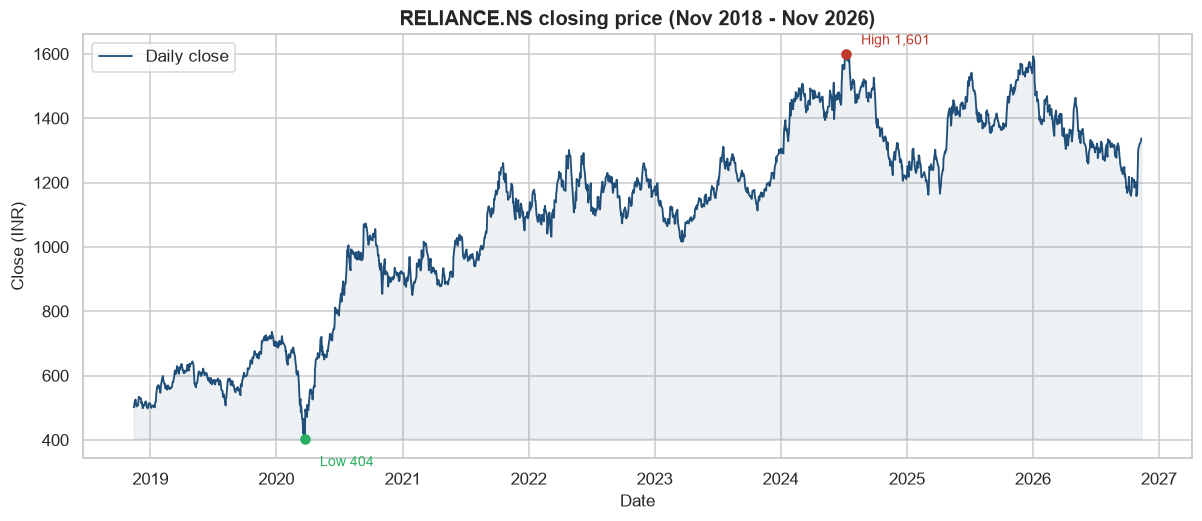

In [3]:
# --- 2.1 Closing price over time -------------------------------------------
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df_raw["Date"], df_raw["Close"], color="#1f4e79", lw=1.2, label="Daily close")
ax.fill_between(df_raw["Date"], df_raw["Close"], df_raw["Close"].min(), color="#1f4e79", alpha=0.08)

peak_idx = df_raw["Close"].idxmax()
trough_idx = df_raw["Close"].idxmin()
ax.scatter(df_raw.loc[peak_idx, "Date"], df_raw.loc[peak_idx, "Close"], color="#c0392b", zorder=5, s=35)
ax.annotate(
    f"High {df_raw.loc[peak_idx, 'Close']:,.0f}",
    (df_raw.loc[peak_idx, "Date"], df_raw.loc[peak_idx, "Close"]),
    textcoords="offset points", xytext=(10, 6), color="#c0392b", fontsize=9, ha="left",
)
ax.scatter(df_raw.loc[trough_idx, "Date"], df_raw.loc[trough_idx, "Close"], color="#27ae60", zorder=5, s=35)
ax.annotate(
    f"Low {df_raw.loc[trough_idx, 'Close']:,.0f}",
    (df_raw.loc[trough_idx, "Date"], df_raw.loc[trough_idx, "Close"]),
    textcoords="offset points", xytext=(10, -18), color="#27ae60", fontsize=9,
)
ax.set_title(f"{TICKER} closing price ({df_raw['Date'].min():%b %Y} - {df_raw['Date'].max():%b %Y})")
ax.set_xlabel("Date")
ax.set_ylabel("Close (INR)")
ax.legend(loc="upper left")
save_fig(fig, "fig01_closing_price.png")
plt.show()

Saved figure -> outputs\figures\fig02_volume.png


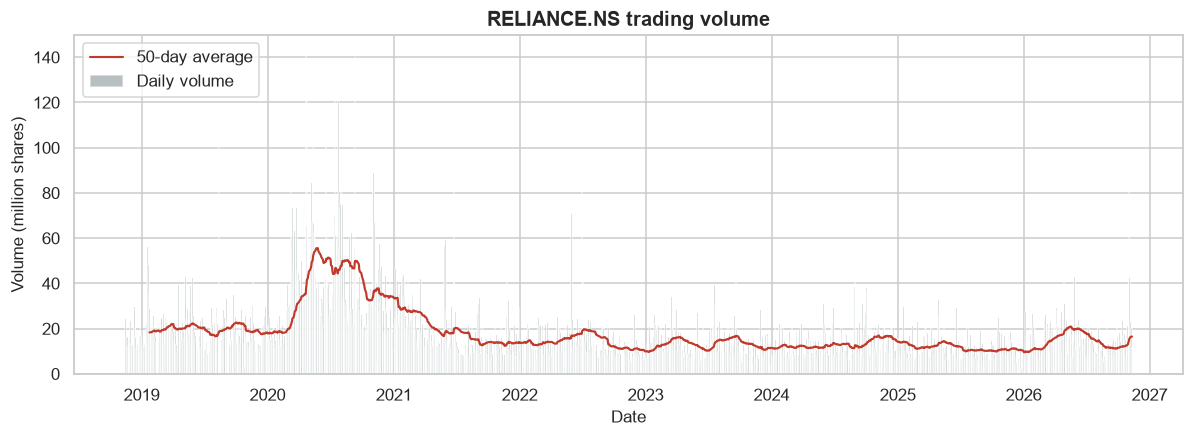

Average daily volume : 18.0M shares
Busiest day          : 2020-04-22 (142.7M shares)


In [4]:
# --- 2.2 Volume -------------------------------------------------------------
volume_m = df_raw["Volume"] / 1e6
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(df_raw["Date"], volume_m, width=1.6, color="#7f8c8d", alpha=0.55, label="Daily volume")
ax.plot(df_raw["Date"], volume_m.rolling(50).mean(), color="#c0392b", lw=1.4, label="50-day average")
ax.set_title(f"{TICKER} trading volume")
ax.set_xlabel("Date")
ax.set_ylabel("Volume (million shares)")
ax.legend(loc="upper left")
save_fig(fig, "fig02_volume.png")
plt.show()

print(f"Average daily volume : {volume_m.mean():.1f}M shares")
print(f"Busiest day          : {df_raw.loc[volume_m.idxmax(), 'Date']:%Y-%m-%d} ({volume_m.max():.1f}M shares)")

Saved figure -> outputs\figures\fig03_moving_averages.png


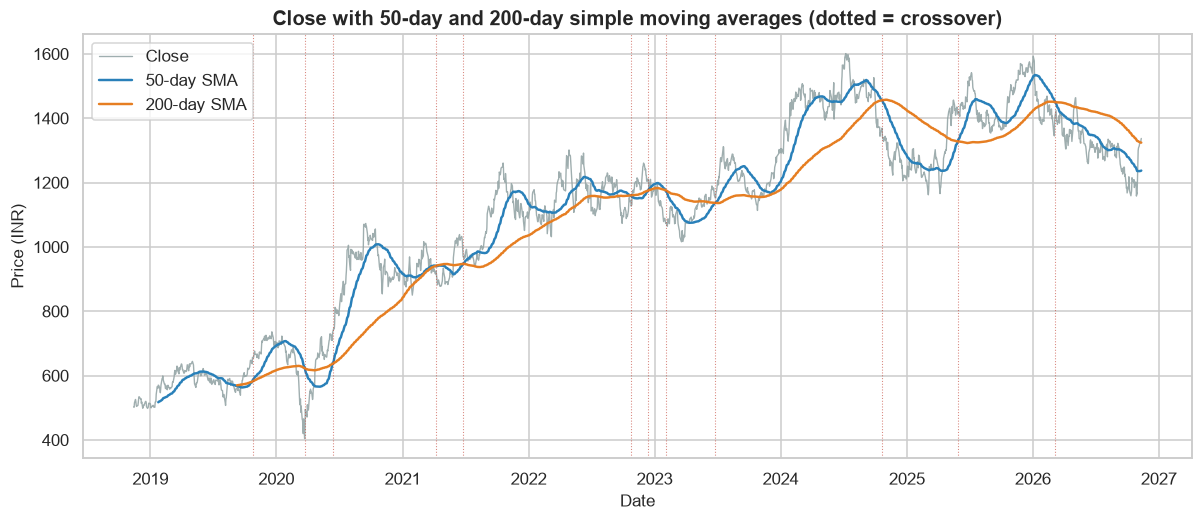

Moving-average crossovers in the sample: 12
Regimes where the 50-day SMA is above the 200-day SMA are commonly called 'uptrends'.


In [5]:
# --- 2.3 50/200-day moving averages ----------------------------------------
ma_df = df_raw.set_index("Date")["Close"].to_frame("Close")
ma_df["SMA_50"] = ma_df["Close"].rolling(50).mean()
ma_df["SMA_200"] = ma_df["Close"].rolling(200).mean()
ma_df["Signal"] = np.where(ma_df["SMA_50"] > ma_df["SMA_200"], 1, 0)
crossovers = ma_df["Signal"].diff().fillna(0)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ma_df.index, ma_df["Close"], color="#95a5a6", lw=0.9, alpha=0.9, label="Close")
ax.plot(ma_df.index, ma_df["SMA_50"], color="#2980b9", lw=1.6, label="50-day SMA")
ax.plot(ma_df.index, ma_df["SMA_200"], color="#e67e22", lw=1.6, label="200-day SMA")
for date in ma_df.index[crossovers != 0]:
    ax.axvline(date, color="#c0392b", lw=0.7, ls=":", alpha=0.6)
ax.set_title("Close with 50-day and 200-day simple moving averages (dotted = crossover)")
ax.set_xlabel("Date")
ax.set_ylabel("Price (INR)")
ax.legend(loc="upper left")
save_fig(fig, "fig03_moving_averages.png")
plt.show()

n_cross = int((crossovers != 0).sum())
print(f"Moving-average crossovers in the sample: {n_cross}")
print("Regimes where the 50-day SMA is above the 200-day SMA are commonly called 'uptrends'.")

Saved figure -> outputs\figures\fig04_returns_distribution.png


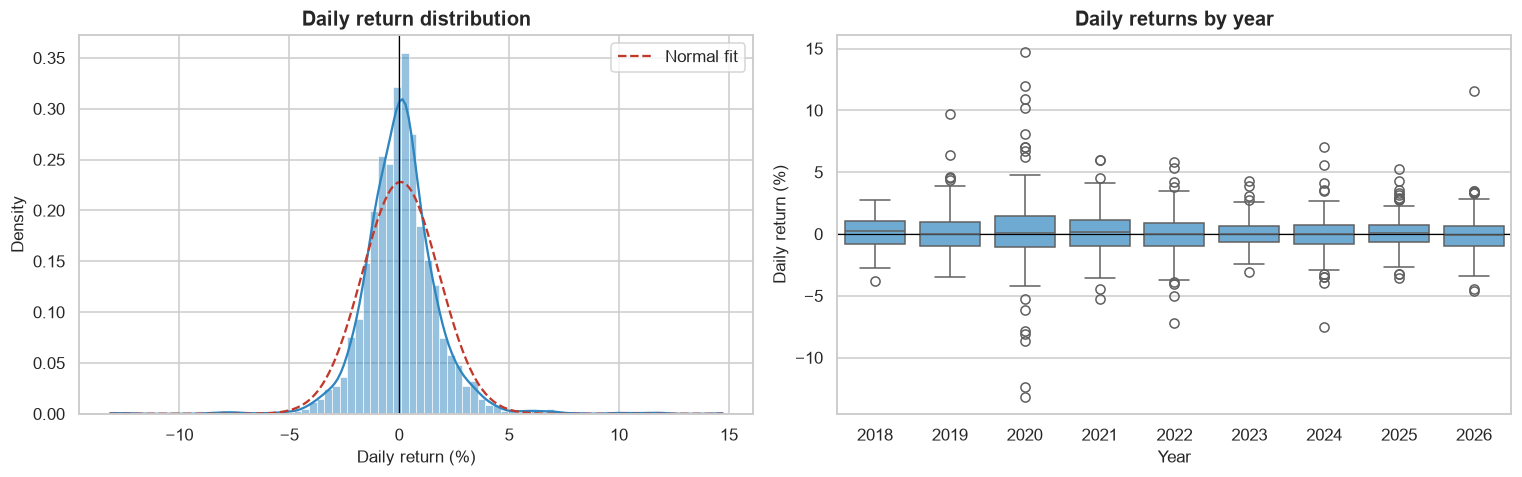

Mean daily return     : +0.065%
Daily volatility      : 1.750%
Annualised volatility : 27.8%
Skewness / excess kurt: 0.55 / 10.32  (normal = 0)
Best / worst day      : +14.72% / -13.15%


In [6]:
# --- 2.4 Daily returns distribution ---------------------------------------
returns = df_raw.set_index("Date")["Close"].pct_change().dropna() * 100  # percent, Date-indexed
mu, sigma = returns.mean(), returns.std()
annual_vol = returns.std() * np.sqrt(252)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(returns, bins=80, kde=True, color="#2e86c1", stat="density", ax=axes[0])
grid = np.linspace(returns.min(), returns.max(), 300)
normal_pdf = np.exp(-0.5 * ((grid - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
axes[0].plot(grid, normal_pdf, color="#c0392b", ls="--", lw=1.5, label="Normal fit")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Daily return distribution")
axes[0].set_xlabel("Daily return (%)")
axes[0].set_ylabel("Density")
axes[0].legend()

sns.boxplot(x=returns.index.year, y=returns.values, color="#5dade2", ax=axes[1])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Daily returns by year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Daily return (%)")
fig.tight_layout()
save_fig(fig, "fig04_returns_distribution.png")
plt.show()

print(f"Mean daily return     : {mu:+.3f}%")
print(f"Daily volatility      : {sigma:.3f}%")
print(f"Annualised volatility : {annual_vol:.1f}%")
print(f"Skewness / excess kurt: {returns.skew():.2f} / {returns.kurtosis():.2f}  (normal = 0)")
print(f"Best / worst day      : {returns.max():+.2f}% / {returns.min():+.2f}%")

Saved figure -> outputs\figures\fig05_correlation_heatmap.png


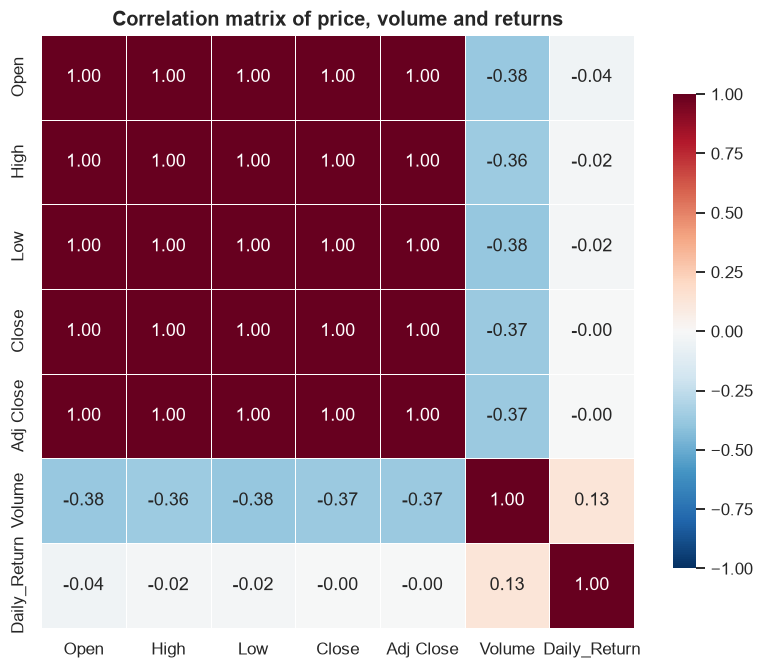

OHLC prices are almost perfectly correlated (they move together intraday).
Correlation between close and volume: -0.373
Correlation between close and daily return: -0.001


In [7]:
# --- 2.5 Correlation heatmap ---------------------------------------------
corr_frame = df_raw[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].copy()
corr_frame["Daily_Return"] = corr_frame["Close"].pct_change()
corr = corr_frame.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("Correlation matrix of price, volume and returns")
save_fig(fig, "fig05_correlation_heatmap.png")
plt.show()

print("OHLC prices are almost perfectly correlated (they move together intraday).")
print(f"Correlation between close and volume: {corr.loc['Close', 'Volume']:.3f}")
print(f"Correlation between close and daily return: {corr.loc['Close', 'Daily_Return']:.3f}")

**EDA takeaways**

- Over the eight years the close rose from about 500 to about 1,340 INR, with a violent COVID crash in
  March 2020. Annualised volatility is **27.8%**, and volatility clusters: the busiest volume day
  (22 Apr 2020, 142.7M shares vs an 18.0M average) sits inside the most turbulent period.
- Daily returns average **+0.065%** with **1.75%** daily volatility. They are close to symmetric but clearly
  **leptokurtic** (excess kurtosis **10.3**): the best and worst days were **+14.7%** and **−13.2%**, far
  beyond what a normal distribution would produce. RMSE and MAPE on prices can therefore look good while
  direction stays very hard.
- Volume has a moderate **negative** correlation with the close (**−0.37**) in this sample; the negative
  correlation mostly reflects that volume was elevated in 2019-2020 when the price was low, while the price
  trended up and volume settled lower; it is a correlation of levels in a trending series, not evidence that
  volume predicts price.
- OHLC price levels are almost perfectly correlated by construction, which is why the model relies on lagged
  closes, returns and indicators rather than treating four near-duplicate price columns as independent evidence.
- Because the price level trends, any model that sees lagged closes can fit the level easily. The honest test is
  the **out-of-sample** section, not the in-sample fit.

## 3. Feature engineering (leakage-free)

Every feature at row `t` uses data up to and including the close of day `t`; the label is the close of
`t + 1`. Concretely:

| Group | Features | Intuition |
|---|---|---|
| Lagged closes | `Lag_1, Lag_2, Lag_3, Lag_5, Lag_10` | Short-term memory / momentum |
| Moving averages | `SMA_5, SMA_10, SMA_20, SMA_50` | Trend and support/resistance levels |
| Momentum | `RSI_14`, `MACD`, `MACD_Signal`, `MACD_Diff` | Overbought/oversold and trend shifts |
| Volatility | `BB_Width`, `Volatility_20` | Band width and 20-day realised volatility |
| Returns | `Daily_Return` | Today's percentage move |

**No leakage rules applied**

- All rolling/EWM indicators are backward-looking (`rolling`, `ewm`, `shift(+n)`).
- The target is created with `shift(-1)` **once**, then rows with missing features are dropped. We never
  shift features forward to "peek" at tomorrow.
- Scaling, imputation (none needed) and hyperparameter search are fitted on the training window only.
- The split is chronological — no shuffling anywhere, and `TimeSeriesSplit` respects time order.

In [8]:
# ---------------------------------------------------------------------------
# Feature builder: one function, reused by the notebook and by predict_next_day()
# ---------------------------------------------------------------------------
FEATURE_COLS = [
    "Lag_1", "Lag_2", "Lag_3", "Lag_5", "Lag_10",
    "SMA_5", "SMA_10", "SMA_20", "SMA_50",
    "RSI_14", "MACD", "MACD_Signal", "MACD_Diff",
    "BB_Width", "Volatility_20", "Daily_Return",
]


def build_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Create leakage-free technical features and the next-day close target.

    Row *i* contains information known at the close of day *i*; ``Target`` is
    the close of day *i + 1*. The last row therefore has a NaN target (tomorrow
    is unknown) - that is the row used for live prediction.
    """
    df = raw.copy().sort_values("Date").drop_duplicates("Date").reset_index(drop=True)
    close = df["Close"].astype(float)

    # Past returns and lagged closes (shift is strictly positive -> past only)
    df["Daily_Return"] = close.pct_change()
    for lag in (1, 2, 3, 5, 10):
        df[f"Lag_{lag}"] = close.shift(lag)

    # Trend: simple moving averages of the close
    for window in (5, 10, 20, 50):
        df[f"SMA_{window}"] = close.rolling(window).mean()

    # Momentum / volatility indicators from the `ta` library (all backward looking)
    df["RSI_14"] = RSIIndicator(close=close, window=14).rsi()
    macd = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)
    df["MACD"] = macd.macd()
    df["MACD_Signal"] = macd.macd_signal()
    df["MACD_Diff"] = macd.macd_diff()

    bands = BollingerBands(close=close, window=20, window_dev=2)
    df["BB_Width"] = (bands.bollinger_hband() - bands.bollinger_lband()) / bands.bollinger_mavg()
    df["Volatility_20"] = df["Daily_Return"].rolling(20).std()

    # Supervised target: NEXT day's closing price
    df["Target"] = close.shift(-1)
    return df


df = build_features(df_raw)

print("NaNs introduced before dropping (warm-up windows):")
nan_counts = df[FEATURE_COLS + ["Target"]].isna().sum()
print(nan_counts[nan_counts > 0].to_string())

n_before = len(df)
df = df.dropna(subset=FEATURE_COLS + ["Target"]).reset_index(drop=True)
print(f"\nDropped {n_before - len(df)} warm-up rows")
print(f"Modelling rows: {len(df):,}  ({df['Date'].min():%Y-%m-%d} -> {df['Date'].max():%Y-%m-%d})")
print(f"Features      : {len(FEATURE_COLS)}")
display(df[["Date", "Close", "Daily_Return", "RSI_14", "MACD", "BB_Width", "Volatility_20", "Target"]].head())

NaNs introduced before dropping (warm-up windows):
Lag_1             1
Lag_2             2
Lag_3             3
Lag_5             5
Lag_10           10
SMA_5             4
SMA_10            9
SMA_20           19
SMA_50           49
RSI_14           13
MACD             25
MACD_Signal      33
MACD_Diff        33
BB_Width         19
Volatility_20    20
Daily_Return      1
Target            1

Dropped 50 warm-up rows
Modelling rows: 1,924  (2019-01-24 -> 2026-11-09)
Features      : 16


,Date,Close,Daily_Return,RSI_14,MACD,BB_Width,Volatility_20,Target
0,2019-01-24,570.292175,0.017247,76.279449,13.478259,0.181693,0.016494,569.629272
1,2019-01-25,569.629272,-0.001162,75.686916,14.860929,0.196956,0.016562,562.108887
2,2019-01-28,562.108887,-0.013202,69.126597,15.174945,0.204410,0.016959,553.468445
3,2019-01-29,553.468445,-0.015371,62.431061,14.558770,0.206543,0.017522,546.633789
4,2019-01-30,546.633789,-0.012349,57.672513,13.364884,0.203665,0.017488,561.011719


In [9]:
# ---------------------------------------------------------------------------
# Leakage and sanity checks
# ---------------------------------------------------------------------------
# (1) Target must be exactly the next row's close.
target_gap = (df["Target"] - df["Close"].shift(-1)).abs()
print(f"Max |Target - next Close| : {target_gap.max():.10f}")
assert target_gap.dropna().max() < 1e-8

# (2) Lag_1 must equal today's close shifted by one row.
assert np.allclose(df["Lag_1"].iloc[1:], df["Close"].iloc[:-1])
print("Lag_1 matches previous close: OK")

# (3) No missing values remain in the modelling frame.
assert df[FEATURE_COLS + ["Target"]].isna().sum().sum() == 0
print("No NaNs in features/target: OK")

# (4) Feature/target scale check: next-day close is close to today's close, as expected.
print(f"Target range: {df['Target'].min():,.1f} - {df['Target'].max():,.1f} INR")
print(f"Mean absolute 1-day move: {(df['Target'] - df['Close']).abs().mean():.2f} INR")

display(df[FEATURE_COLS].describe().T.round(3))

Max |Target - next Close| : 0.0000000000
Lag_1 matches previous close: OK
No NaNs in features/target: OK
Target range: 404.2 - 1,600.9 INR
Mean absolute 1-day move: 12.51 INR


,count,mean,std,min,25%,50%,75%,max
Lag_1,1924.0,1113.399,285.461,404.158,940.000,1169.770,1322.000,1600.900
Lag_2,1924.0,1113.006,285.696,404.158,939.198,1169.470,1322.000,1600.900
Lag_3,1924.0,1112.617,285.931,404.158,938.702,1168.783,1322.000,1600.900
Lag_5,1924.0,1111.807,286.477,404.158,936.504,1167.888,1322.000,1600.900
Lag_10,1924.0,1110.019,288.070,404.158,934.030,1167.613,1322.000,1600.900
SMA_5,1924.0,1113.007,285.276,432.626,939.482,1171.063,1318.350,1590.555
SMA_10,1924.0,1112.040,285.551,455.765,936.760,1169.668,1316.962,1585.670
SMA_20,1924.0,1110.220,286.329,482.441,932.795,1168.993,1312.903,1559.136
SMA_50,1924.0,1104.773,288.675,517.050,933.477,1169.359,1328.042,1534.366
RSI_14,1924.0,51.718,12.222,16.991,42.909,51.204,61.106,82.643


## 4. Time-based split and scaling

The first 80% of rows are training data and the last 20% is held out. No shuffling: the test set is strictly
*after* the training set, which is the only honest way to evaluate a time-series forecast.

`StandardScaler` is fitted on `X_train` only (and reused for the test set and for live predictions). Tree
models use the unscaled matrix because they are invariant to monotone feature scaling; Linear Regression and
the LSTM use the scaled matrix.

In [10]:
# ---------------------------------------------------------------------------
# Chronological 80/20 split
# ---------------------------------------------------------------------------
TRAIN_FRAC = 0.80


def time_based_split(frame: pd.DataFrame, train_frac: float = 0.8):
    """Split a time-ordered frame into the first `train_frac` rows and the rest."""
    split_idx = int(len(frame) * train_frac)
    return frame.iloc[:split_idx].copy(), frame.iloc[split_idx:].copy()


train_df, test_df = time_based_split(df, TRAIN_FRAC)

X_train = train_df[FEATURE_COLS].to_numpy(dtype=float)
y_train = train_df["Target"].to_numpy(dtype=float)
X_test = test_df[FEATURE_COLS].to_numpy(dtype=float)
y_test = test_df["Target"].to_numpy(dtype=float)

# Scaler: fit on training data ONLY, then applied to test and future rows.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# The target of the naive baseline is today's close, so keep it aligned with y_test.
prev_close_test = test_df["Close"].to_numpy(dtype=float)

assert train_df["Date"].max() < test_df["Date"].min(), "Split is not chronological!"
assert len(train_df) + len(test_df) == len(df)

split_summary = pd.DataFrame(
    {
        "rows": [len(train_df), len(test_df)],
        "share": [len(train_df) / len(df), len(test_df) / len(df)],
        "start": [train_df["Date"].min().date(), test_df["Date"].min().date()],
        "end": [train_df["Date"].max().date(), test_df["Date"].max().date()],
    },
    index=["Train (80%)", "Test (20%)"],
)
display(split_summary)
print(f"Train targets mean / std : {y_train.mean():,.2f} / {y_train.std():,.2f} INR")
print(f"Test  targets mean / std : {y_test.mean():,.2f} / {y_test.std():,.2f} INR")

,rows,share,start,end
Train (80%),1539,0.799896,2019-01-24,2025-04-22
Test (20%),385,0.200104,2025-04-23,2026-11-09


Train targets mean / std : 1,046.32 / 276.08 INR
Test  targets mean / std : 1,385.50 / 94.84 INR


## 5. Models

Five forecasters, weakest-to-strongest in complexity:

1. **Naive baseline** — tomorrow's close = today's close. If a model cannot beat this, it has learned nothing.
2. **Linear Regression** — interpretable linear benchmark on standardised features.
3. **Random Forest** — non-linear bagged trees; captures thresholds and interactions.
4. **XGBoost** — gradient-boosted trees; usually the strongest tabular model.
5. **LSTM** — a 60-day sequence model that can learn temporal dynamics directly (skipped if TensorFlow is absent).
   Its price target is standardised (using training statistics only) for stable training and inverse-transformed
   back to INR before scoring.

Hyperparameters for the tree models are tuned with `GridSearchCV` using `TimeSeriesSplit(n_splits=3)`
**inside the training window only**; the test set is untouched until evaluation. The validation fold is always
later in time than its training fold, so tuning respects causality.

In [11]:
# ---------------------------------------------------------------------------
# (a) Naive baseline: tomorrow's close = today's close
# ---------------------------------------------------------------------------
predictions = {}
predictions["Naive (tomorrow = today)"] = prev_close_test.copy()
print(f"Stored naive predictions for {len(predictions['Naive (tomorrow = today)']):,} test days.")

Stored naive predictions for 385 test days.


In [12]:
# ---------------------------------------------------------------------------
# (b) Linear Regression
# ---------------------------------------------------------------------------
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
predictions["Linear Regression"] = lr_model.predict(X_test_scaled)

train_r2 = lr_model.score(X_train_scaled, y_train)
print(f"Linear Regression fitted. Train R2 = {train_r2:.5f}")
print("\nLargest standardised coefficients:")
coefs = pd.Series(lr_model.coef_, index=FEATURE_COLS).reindex(
    pd.Series(lr_model.coef_, index=FEATURE_COLS).abs().sort_values(ascending=False).index
)
display(coefs.head(8).round(2).to_frame("coefficient"))

Linear Regression fitted. Train R2 = 0.99600

Largest standardised coefficients:


,coefficient
SMA_20,251.89
SMA_5,118.28
Lag_2,-91.22
Lag_3,-58.27
Lag_5,-30.14
Lag_1,29.27
SMA_10,26.61
SMA_50,23.62


In [13]:
# ---------------------------------------------------------------------------
# (c) Random Forest with light hyperparameter tuning (TimeSeriesSplit)
# ---------------------------------------------------------------------------
tscv = TimeSeriesSplit(n_splits=3)

rf_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 3],
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=SEED, n_jobs=1),
    param_grid=rf_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    # n_jobs=1 keeps the search deterministic and avoids joblib/loky deadlocks
    # on Windows; the grid is small enough that parallelism is not needed.
    n_jobs=1,
    refit=True,
)
rf_search.fit(X_train, y_train)  # unscaled: trees do not need scaling
rf_model = rf_search.best_estimator_
predictions["Random Forest"] = rf_model.predict(X_test)

print(f"Random Forest best params : {rf_search.best_params_}")
print(f"Random Forest CV RMSE     : {-rf_search.best_score_:,.2f} INR")

Random Forest best params : {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}
Random Forest CV RMSE     : 101.27 INR


In [14]:
# ---------------------------------------------------------------------------
# (d) XGBoost with light hyperparameter tuning (TimeSeriesSplit)
# ---------------------------------------------------------------------------
xgb_grid = {
    "n_estimators": [400],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

xgb_search = GridSearchCV(
    estimator=XGBRegressor(
        random_state=SEED,
        tree_method="hist",
        objective="reg:squarederror",
        n_jobs=1,
        verbosity=0,
    ),
    param_grid=xgb_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    refit=True,
)
xgb_search.fit(X_train, y_train)
xgb_model = xgb_search.best_estimator_
predictions["XGBoost"] = xgb_model.predict(X_test)

print(f"XGBoost best params : {xgb_search.best_params_}")
print(f"XGBoost CV RMSE     : {-xgb_search.best_score_:,.2f} INR")

XGBoost best params : {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8}
XGBoost CV RMSE     : 102.90 INR


In [15]:
# ---------------------------------------------------------------------------
# (e) LSTM on 60-day windows (optional - requires TensorFlow)
# ---------------------------------------------------------------------------
WINDOW = 60
LSTM_EPOCHS = 40
lstm_model = None
lstm_history = None
y_scaler = None  # target scaler for the LSTM (prices are far from zero)

if TF_AVAILABLE:
    # Scale with the scalers fitted on the training rows only, then build windows.
    X_all_scaled = scaler.transform(df[FEATURE_COLS].to_numpy(dtype=float))
    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()
    y_all_scaled = y_scaler.transform(df["Target"].to_numpy(dtype=float).reshape(-1, 1)).ravel()
    n_train = len(train_df)

    def make_sequences(X, y, first_target, last_target, window):
        """Windows X[i-window:i] -> y[i] for target rows in [first_target, last_target)."""
        xs, ys, positions = [], [], []
        for i in range(max(first_target, window), last_target):
            xs.append(X[i - window:i])
            ys.append(y[i])
            positions.append(i)
        return np.asarray(xs), np.asarray(ys), np.asarray(positions)

    X_tr_seq, y_tr_seq, _ = make_sequences(X_all_scaled, y_all_scaled, 0, n_train, WINDOW)
    X_te_seq, _, pos_te = make_sequences(X_all_scaled, y_all_scaled, n_train, len(df), WINDOW)

    # Chronological validation slice for early stopping (last 15% of the training window).
    val_cut = int(len(X_tr_seq) * 0.85)

    lstm_model = keras.Sequential(
        [
            layers.Input(shape=(WINDOW, len(FEATURE_COLS))),
            layers.LSTM(48),
            layers.Dropout(0.2),
            layers.Dense(16, activation="relu"),
            layers.Dense(1),
        ],
        name="lstm_price_predictor",
    )
    lstm_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    lstm_model.summary()

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True, verbose=0
    )
    lstm_history = lstm_model.fit(
        X_tr_seq[:val_cut],
        y_tr_seq[:val_cut],
        validation_data=(X_tr_seq[val_cut:], y_tr_seq[val_cut:]),
        epochs=LSTM_EPOCHS,
        batch_size=32,
        shuffle=False,  # never shuffle a time series
        callbacks=[early_stop],
        verbose=0,
    )

    # Predictions come back in standardised units - map them to INR before scoring.
    lstm_test_scaled = lstm_model.predict(X_te_seq, verbose=0).ravel()
    lstm_test_pred = y_scaler.inverse_transform(lstm_test_scaled.reshape(-1, 1)).ravel()
    lstm_series = pd.Series(lstm_test_pred, index=df["Date"].iloc[pos_te])
    predictions["LSTM (60-day window)"] = lstm_series.reindex(test_df["Date"]).to_numpy()

    print(f"LSTM trained for {len(lstm_history.history['loss'])} epochs (early stopping).")
    print(f"Best validation MSE (standardised): {min(lstm_history.history['val_loss']):.5f}")
    print(f"Test windows        : {X_te_seq.shape[0]:,} x {WINDOW} days x {X_te_seq.shape[2]} features")
else:
    print("TensorFlow is not available: LSTM skipped. All other models are still evaluated.")

Model: "lstm_price_predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48)             │        12,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,281 (51.88 KB)

 Trainable params: 13,281 (51.88 KB)

 Non-trainable params: 0 (0.00 B)

LSTM trained for 24 epochs (early stopping).
Best validation MSE (standardised): 0.01722
Test windows        : 385 x 60 days x 16 features


## 6. Evaluation

Four error metrics and one behavioural metric, all on the untouched 20% test set:

- **RMSE** (INR) — penalises large misses; same units as the price.
- **MAE** (INR) — average absolute error, easier to interpret.
- **MAPE (%)** — scale-free average percentage error.
- **R²** — fraction of variance explained; can be negative for a bad model.
- **Directional accuracy (%)** — share of days where the predicted sign of (tomorrow − today) is correct.

The naive forecast predicts *no change*, so it has **no directional call at all**: its directional accuracy is
reported as **N/A** (not 0%), because "correct direction" is undefined when the forecast is exactly flat.
The honest directional benchmark is **50%** (and 49.6% of test days were up days, so always guessing "up" is
not a shortcut either).

In [16]:
# ---------------------------------------------------------------------------
# Metric helpers
# ---------------------------------------------------------------------------
def regression_metrics(y_true, y_pred, prev_close=None) -> dict:
    """RMSE, MAE, MAPE, R2 and directional accuracy for one set of predictions."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if prev_close is not None:
        prev_close = np.asarray(prev_close, dtype=float)[mask]

    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    r2 = float(r2_score(y_true, y_pred))

    if prev_close is None:
        directional = float("nan")
    else:
        actual_direction = np.sign(y_true - prev_close)
        predicted_direction = np.sign(y_pred - prev_close)
        directional = float(np.mean(actual_direction == predicted_direction) * 100)

    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "R2": r2, "Directional Acc (%)": directional}


def build_results_table(pred_dict: dict) -> pd.DataFrame:
    """Score every model on the test set.

    The naive forecast has no directional call (it predicts zero change), so it
    is scored with ``prev_close=None`` and its directional accuracy stays NaN.
    """
    rows = []
    for name, pred in pred_dict.items():
        prev = None if name.startswith("Naive") else prev_close_test
        rows.append({"Model": name, **regression_metrics(y_test, pred, prev)})
    return pd.DataFrame(rows).set_index("Model").sort_values("RMSE")


def format_results_table(frame: pd.DataFrame, decimals: int = 2,
                         direction_decimals: int = 2) -> pd.DataFrame:
    """Return a display/export copy with 'N/A' where a metric is undefined."""
    out = frame.copy()
    for col in out.columns:
        if col == "Directional Acc (%)":
            out[col] = out[col].map(
                lambda v: "N/A" if pd.isna(v) else f"{float(v):.{direction_decimals}f}"
            )
        else:
            out[col] = out[col].astype(float).round(decimals)
    return out


def save_results(frame: pd.DataFrame, path: Path = OUT_DIR / "model_comparison.csv") -> Path:
    """Persist the comparison table, writing 'N/A' for undefined metrics."""
    format_results_table(frame, decimals=4, direction_decimals=4).to_csv(path)
    return path


results = build_results_table(predictions)
comparison_path = save_results(results)
print(f"Comparison table saved -> {comparison_path.relative_to(PROJECT_ROOT)}")
print("(directional accuracy is N/A for the naive forecast: it predicts no change)")
display(format_results_table(results))

naive_rmse = results.loc["Naive (tomorrow = today)", "RMSE"]
print(f"\nNaive baseline RMSE: {naive_rmse:,.2f} INR")
for name in results.index:
    if name.startswith("Naive"):
        continue
    gain = (naive_rmse - results.loc[name, "RMSE"]) / naive_rmse * 100
    print(f"  {name:<38s} RMSE vs naive: {gain:+.2f}%")

up_day_share = float(np.mean(y_test > prev_close_test) * 100)
print(f"\nTest days that were up: {up_day_share:.1f}% (always-'up' direction benchmark)")

Comparison table saved -> outputs\model_comparison.csv
(directional accuracy is N/A for the naive forecast: it predicts no change)


,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
Model,,,,,
Naive (tomorrow = today),19.00,13.53,0.99,0.96,N/A
Linear Regression,19.77,14.23,1.04,0.96,49.87
XGBoost,22.74,17.05,1.24,0.94,50.39
Random Forest,27.00,20.68,1.50,0.92,47.01
LSTM (60-day window),40.81,31.56,2.26,0.81,48.31



Naive baseline RMSE: 19.00 INR
  Linear Regression                      RMSE vs naive: -4.03%
  XGBoost                                RMSE vs naive: -19.67%
  Random Forest                          RMSE vs naive: -42.10%
  LSTM (60-day window)                   RMSE vs naive: -114.77%

Test days that were up: 49.6% (always-'up' direction benchmark)


Saved figure -> outputs\figures\fig06_model_comparison.png


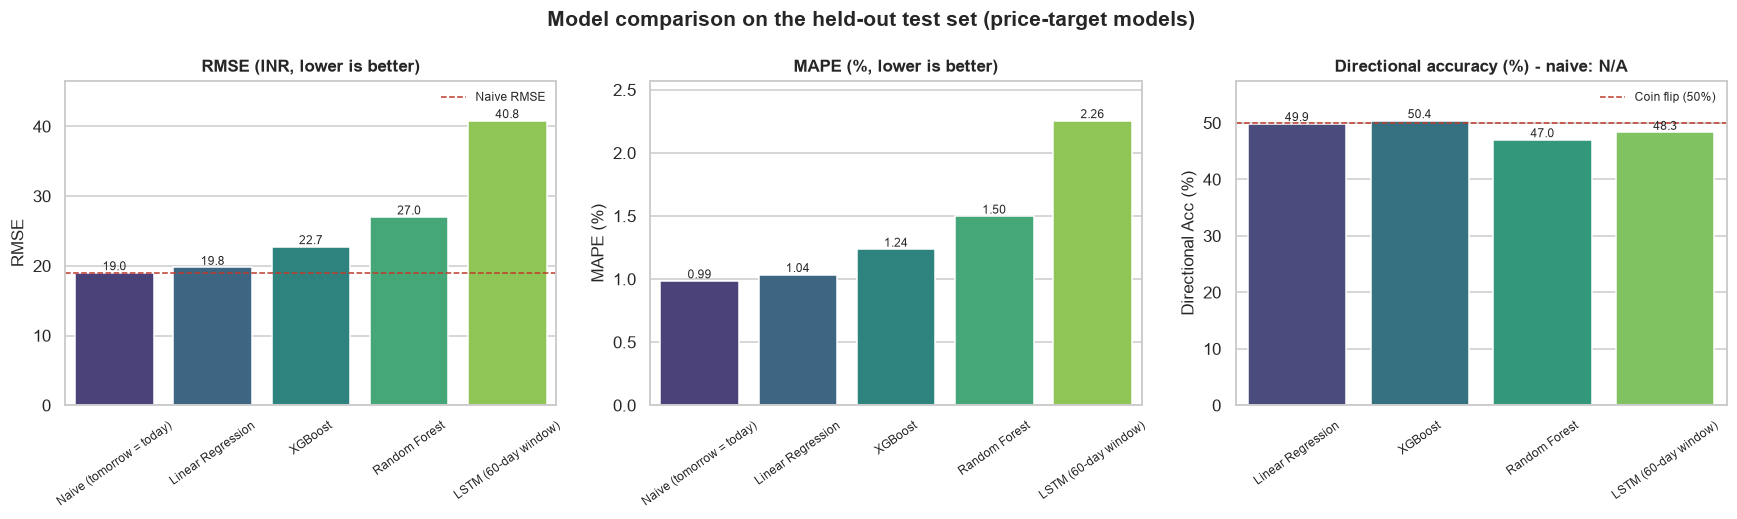

In [17]:
# ---------------------------------------------------------------------------
# Comparison bar chart
# ---------------------------------------------------------------------------
plot_df = results[["RMSE", "MAPE (%)"]].copy()
direction_df = results.dropna(subset=["Directional Acc (%)"])  # naive has no direction call
bar_colors = sns.color_palette("viridis", n_colors=len(plot_df))
direction_colors = sns.color_palette("viridis", n_colors=len(direction_df))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
panels = [
    ("RMSE", "RMSE (INR, lower is better)", "{:.1f}"),
    ("MAPE (%)", "MAPE (%, lower is better)", "{:.2f}"),
]
for ax, (col, title, fmt) in zip(axes[:2], panels):
    sns.barplot(
        x=plot_df.index, y=plot_df[col], hue=plot_df.index,
        palette=bar_colors, legend=False, ax=ax,
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.margins(y=0.14)
    for i, value in enumerate(plot_df[col].to_numpy()):
        ax.text(i, value, fmt.format(value), ha="center", va="bottom", fontsize=8)

# Directional accuracy: the naive forecast predicts no change, so it has no bar here.
sns.barplot(
    x=direction_df.index, y=direction_df["Directional Acc (%)"], hue=direction_df.index,
    palette=direction_colors, legend=False, ax=axes[2],
)
axes[2].set_title("Directional accuracy (%) - naive: N/A", fontsize=11)
axes[2].set_xlabel("")
axes[2].set_ylabel("Directional Acc (%)")
axes[2].tick_params(axis="x", rotation=35, labelsize=8)
axes[2].margins(y=0.14)
for i, value in enumerate(direction_df["Directional Acc (%)"].to_numpy()):
    axes[2].text(i, value, f"{value:.1f}", ha="center", va="bottom", fontsize=8)

axes[0].axhline(naive_rmse, color="#c0392b", ls="--", lw=1, label="Naive RMSE")
axes[0].legend(loc="upper right", fontsize=8, frameon=False)
axes[2].axhline(50, color="#c0392b", ls="--", lw=1, label="Coin flip (50%)")
axes[2].legend(loc="upper right", fontsize=8, frameon=False)

fig.suptitle("Model comparison on the held-out test set (price-target models)", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig06_model_comparison.png")
plt.show()

## 7. Diagnostics for the best fitted model (price-target formulation)

- **Actual vs predicted** on the full test set and on the last 120 trading days (a zoomed view shows whether
  the model tracks turning points or just lags the level).
- **Residuals** over time and their distribution — systematic bias would show up as a non-zero mean or a trend.
- **Feature importance** for the two tree models — which indicators actually drive the forecasts.

In [18]:
# ---------------------------------------------------------------------------
# Pick the best fitted model in the price-target formulation (naive excluded: it is a benchmark, not a fitted model)
# ---------------------------------------------------------------------------
fitted_results = results.drop(index="Naive (tomorrow = today)")
best_model_name = str(fitted_results["RMSE"].idxmin())
best_pred = np.asarray(predictions[best_model_name], dtype=float)
best_rmse = float(results.loc[best_model_name, "RMSE"])
best_mae = float(results.loc[best_model_name, "MAE"])

print(f"Best price-target fitted model: {best_model_name}")
print(f"  RMSE {best_rmse:,.2f} INR | MAE {best_mae:,.2f} INR | R2 {results.loc[best_model_name, 'R2']:.4f}")

models = {"Linear Regression": lr_model, "Random Forest": rf_model, "XGBoost": xgb_model}
if lstm_model is not None:
    models["LSTM (60-day window)"] = lstm_model
assert best_model_name in models

Best price-target fitted model: Linear Regression
  RMSE 19.77 INR | MAE 14.23 INR | R2 0.9566


Saved figure -> outputs\figures\fig07_actual_vs_predicted.png


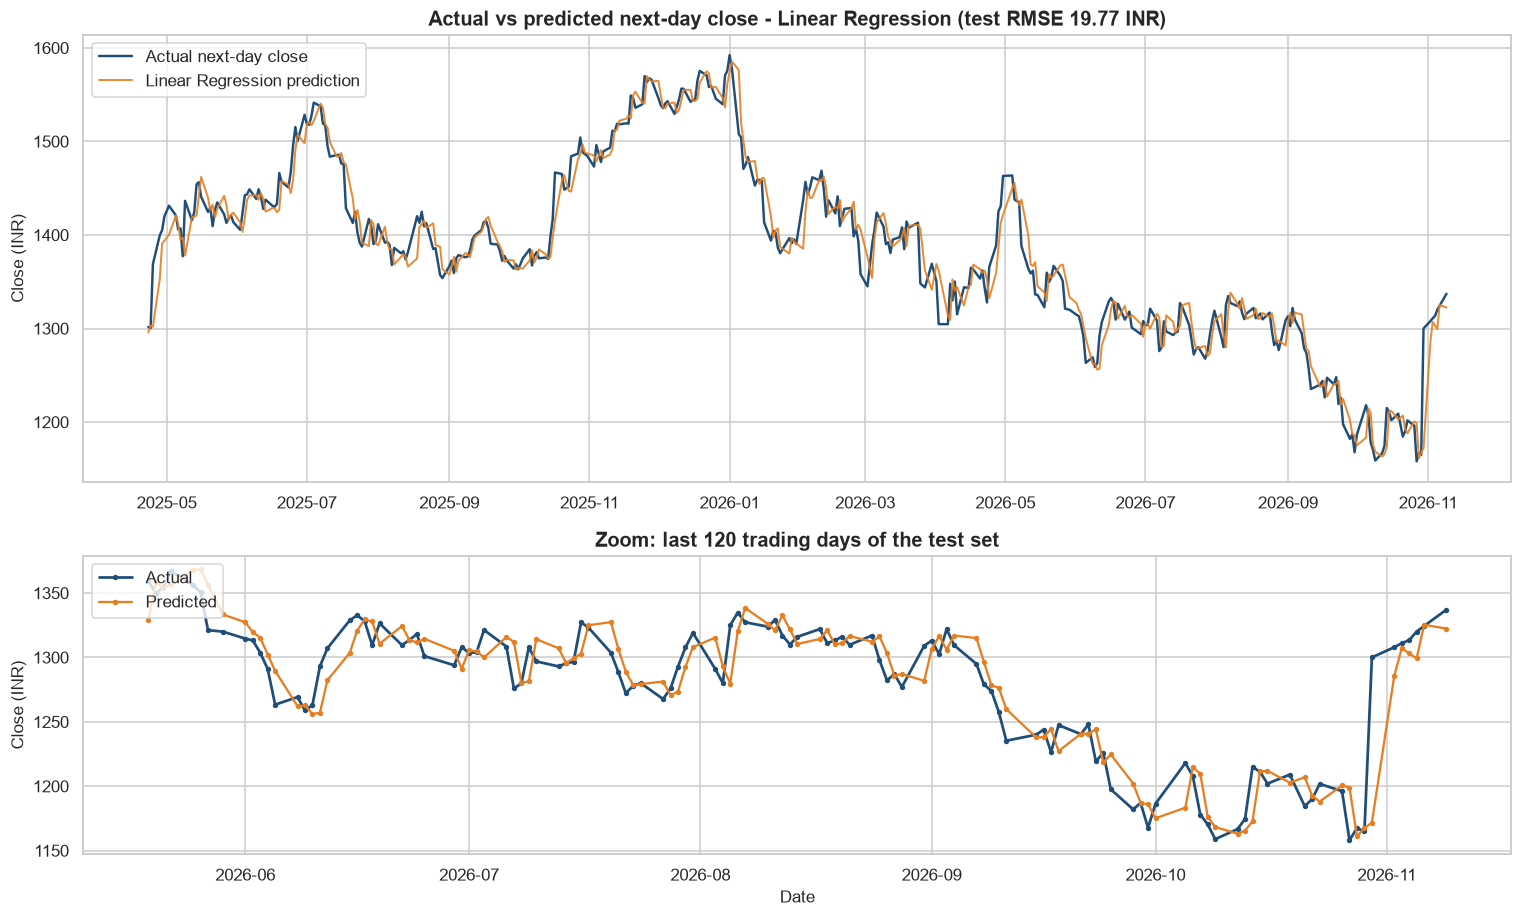

In [19]:
# --- 7.1 Actual vs predicted for the best fitted model ---------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), gridspec_kw={"height_ratios": [1.5, 1]})

axes[0].plot(test_df["Date"], y_test, color="#1f4e79", lw=1.6, label="Actual next-day close")
axes[0].plot(test_df["Date"], best_pred, color="#e67e22", lw=1.3, alpha=0.9, label=f"{best_model_name} prediction")
axes[0].set_title(f"Actual vs predicted next-day close - {best_model_name} (test RMSE {best_rmse:,.2f} INR)")
axes[0].set_ylabel("Close (INR)")
axes[0].legend(loc="upper left")

zoom = 120
axes[1].plot(test_df["Date"].iloc[-zoom:], y_test[-zoom:], color="#1f4e79", lw=1.8, marker="o", ms=2.5, label="Actual")
axes[1].plot(test_df["Date"].iloc[-zoom:], best_pred[-zoom:], color="#e67e22", lw=1.5, marker="o", ms=2.5, label="Predicted")
axes[1].set_title(f"Zoom: last {zoom} trading days of the test set")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Close (INR)")
axes[1].legend(loc="upper left")

fig.tight_layout()
save_fig(fig, "fig07_actual_vs_predicted.png")
plt.show()

Saved figure -> outputs\figures\fig08_residuals.png


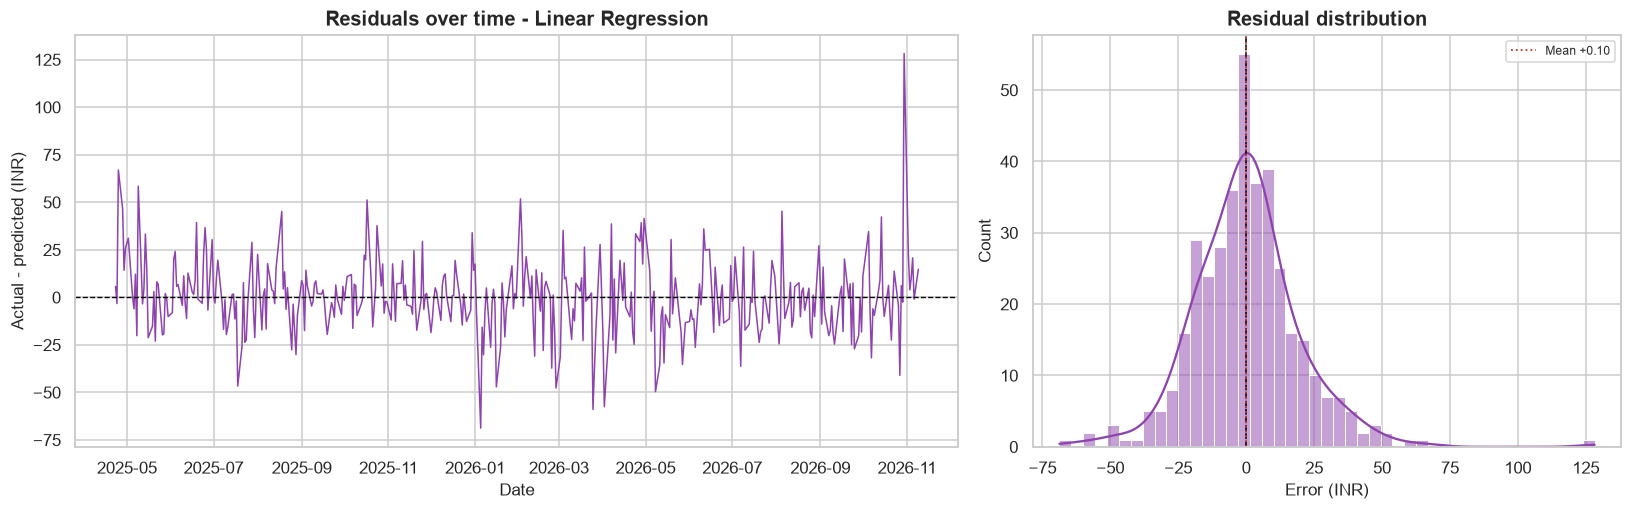

Residual mean  : +0.10 INR
Residual std   : 19.77 INR
Largest miss   : 128.24 INR


In [20]:
# --- 7.2 Residual diagnostics ----------------------------------------------
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

axes[0].plot(test_df["Date"], residuals, color="#8e44ad", lw=1.0)
axes[0].axhline(0, color="black", lw=0.9, ls="--")
axes[0].set_title(f"Residuals over time - {best_model_name}")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Actual - predicted (INR)")

sns.histplot(residuals, bins=45, kde=True, color="#8e44ad", ax=axes[1])
axes[1].axvline(0, color="black", lw=1, ls="--")
axes[1].axvline(residuals.mean(), color="#c0392b", lw=1.2, ls=":", label=f"Mean {residuals.mean():+.2f}")
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Error (INR)")
axes[1].legend(fontsize=8)

fig.tight_layout()
save_fig(fig, "fig08_residuals.png")
plt.show()

print(f"Residual mean  : {residuals.mean():+.2f} INR")
print(f"Residual std   : {residuals.std():.2f} INR")
print(f"Largest miss   : {np.abs(residuals).max():,.2f} INR")

Saved figure -> outputs\figures\fig09_feature_importance.png


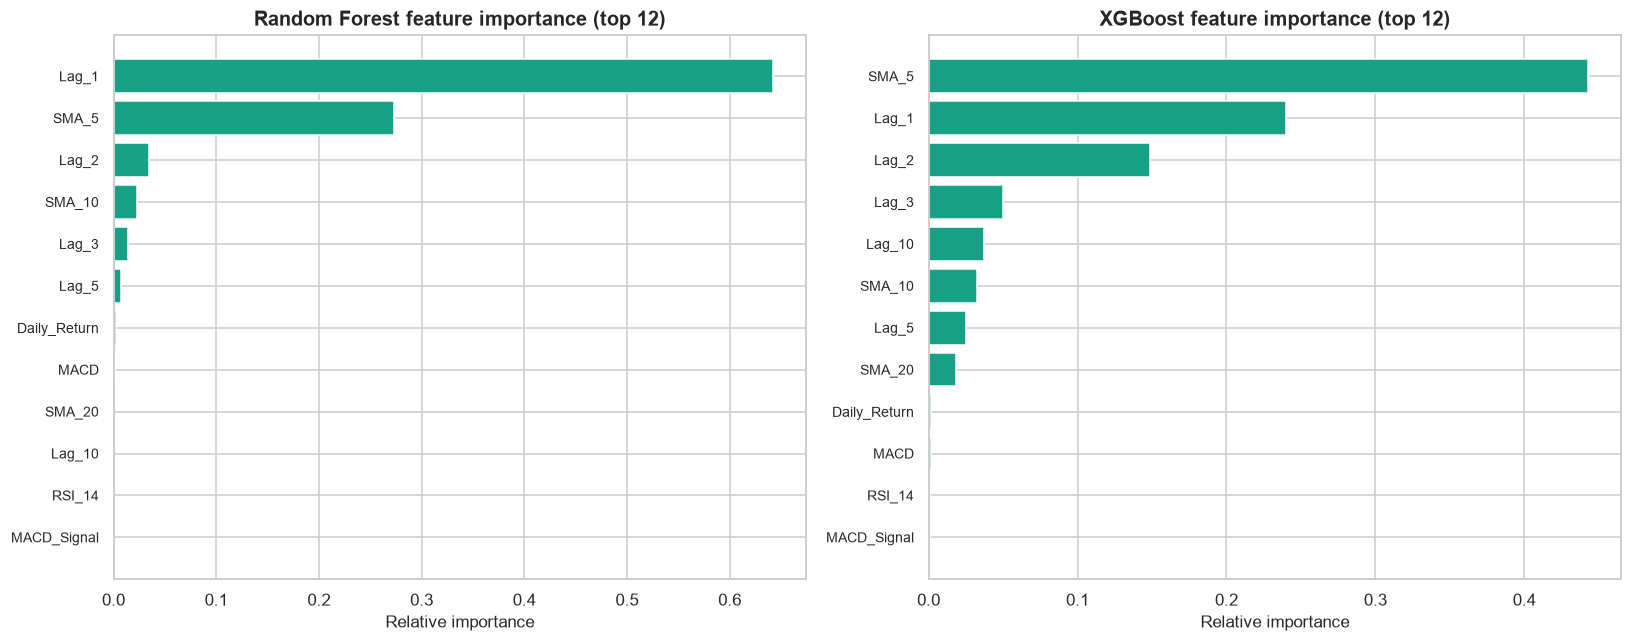

Top XGBoost features:
SMA_5     0.4430
Lag_1     0.2400
Lag_2     0.1486
Lag_3     0.0497
Lag_10    0.0370
SMA_10    0.0324


In [21]:
# --- 7.3 Feature importance for the tree models ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
importance_models = [("Random Forest", rf_model), ("XGBoost", xgb_model)]
for ax, (name, model) in zip(axes, importance_models):
    importance = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values().tail(12)
    ax.barh(importance.index, importance.to_numpy(), color="#16a085")
    ax.set_title(f"{name} feature importance (top 12)")
    ax.set_xlabel("Relative importance")
    ax.tick_params(axis="y", labelsize=9)

fig.tight_layout()
save_fig(fig, "fig09_feature_importance.png")
plt.show()

print("Top XGBoost features:")
print(
    pd.Series(xgb_model.feature_importances_, index=FEATURE_COLS)
    .sort_values(ascending=False)
    .head(6)
    .round(4)
    .to_string()
)

Saved figure -> outputs\figures\fig10_lstm_training.png


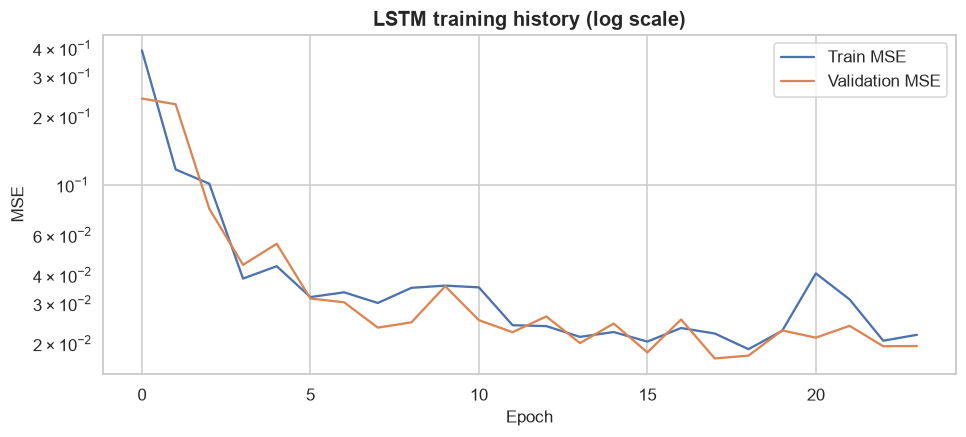

In [22]:
# --- 7.4 LSTM learning curve (only if TensorFlow was available) ------------
if lstm_history is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(lstm_history.history["loss"], label="Train MSE")
    ax.plot(lstm_history.history["val_loss"], label="Validation MSE")
    ax.set_yscale("log")
    ax.set_title("LSTM training history (log scale)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    save_fig(fig, "fig10_lstm_training.png")
    plt.show()
else:
    print("Skipped: LSTM was not trained.")

> **Note on diagnostics vs deployment.** The diagnostics shown above are for the **price-target Linear Regression**, while the saved deployment model is **Linear Regression (return target)**. The figure below shows the diagnostics for the return-target model (actual vs predicted on the test set, plus residuals over time).

Saved figure -> outputs\figures\fig14_return_model_diagnostics.png


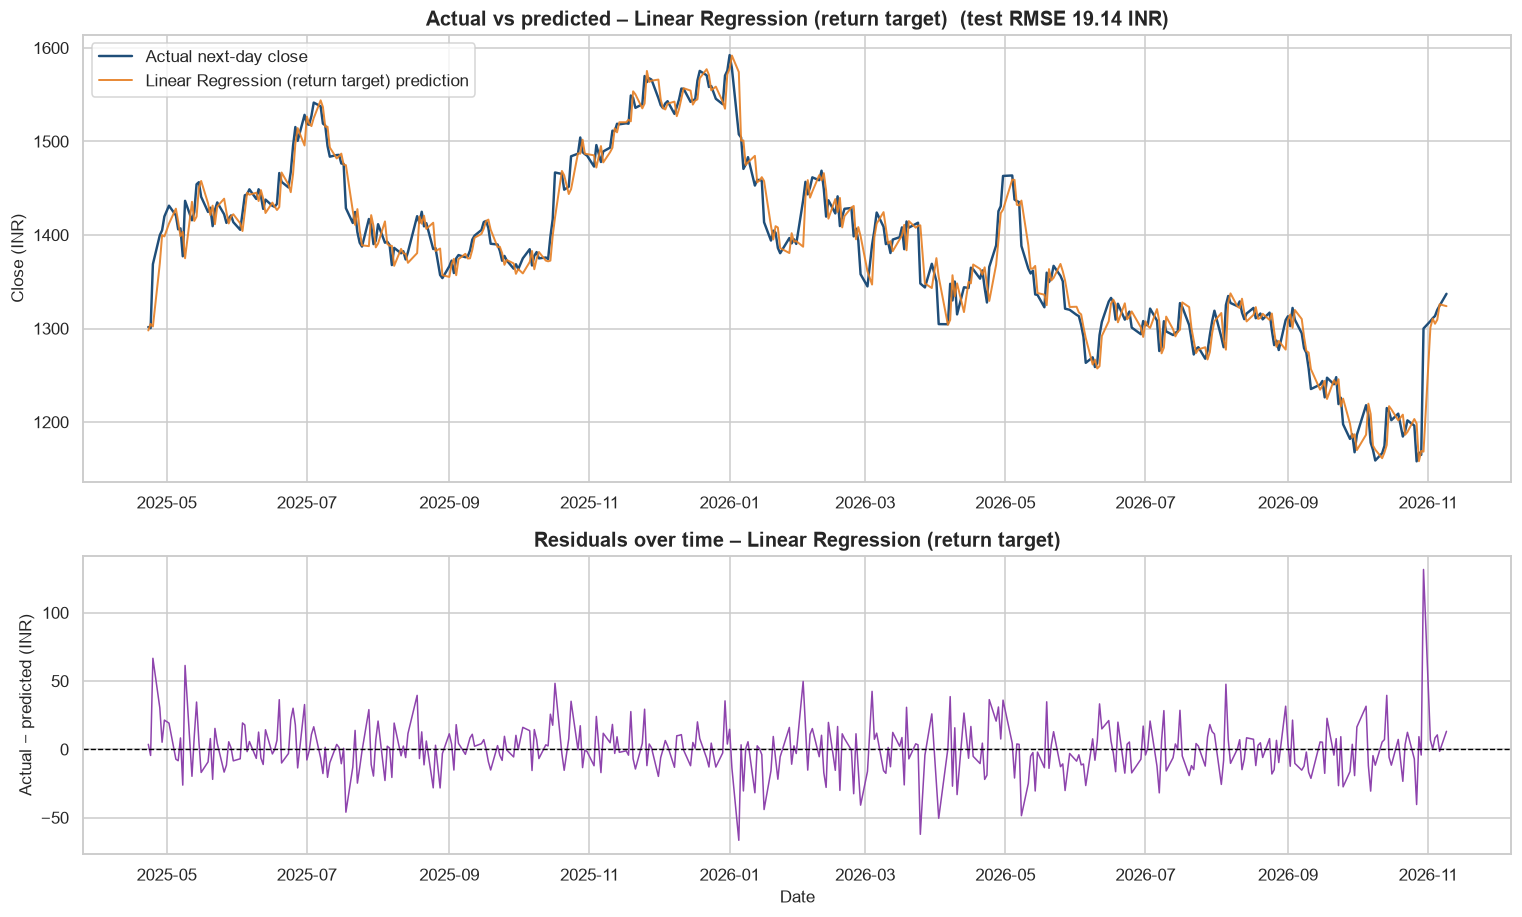

Return-target LR residual mean : +0.36 INR
Return-target LR residual std  : 19.13 INR


In [23]:
# --- 7.5 Return-target model diagnostics (Linear Regression) ----------------
# The saved deployment model is Linear Regression (return target).
# We fit this formulation and evaluate actual vs predicted on the test set, plus residuals over time.
target_return_diag = (df["Target"] / df["Close"] - 1.0).to_numpy(dtype=float)
r_train_diag = target_return_diag[:len(train_df)]
lr_return_diag = LinearRegression().fit(X_train_scaled, r_train_diag)
ret_pred = test_df["Close"].to_numpy(dtype=float) * (1.0 + lr_return_diag.predict(X_test_scaled))
ret_resid = y_test - ret_pred

fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), gridspec_kw={"height_ratios": [1.5, 1]})

axes[0].plot(test_df["Date"], y_test, color="#1f4e79", lw=1.6, label="Actual next-day close")
axes[0].plot(test_df["Date"], ret_pred, color="#e67e22", lw=1.3, alpha=0.9,
             label="Linear Regression (return target) prediction")
ret_rmse = float(np.sqrt(mean_squared_error(y_test, ret_pred)))
axes[0].set_title(f"Actual vs predicted – Linear Regression (return target)  "
                  f"(test RMSE {ret_rmse:,.2f} INR)")
axes[0].set_ylabel("Close (INR)")
axes[0].legend(loc="upper left")

axes[1].plot(test_df["Date"], ret_resid, color="#8e44ad", lw=1.0)
axes[1].axhline(0, color="black", lw=0.9, ls="--")
axes[1].set_title("Residuals over time – Linear Regression (return target)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Actual − predicted (INR)")

fig.tight_layout()
save_fig(fig, "fig14_return_model_diagnostics.png")
plt.show()

print(f"Return-target LR residual mean : {ret_resid.mean():+.2f} INR")
print(f"Return-target LR residual std  : {ret_resid.std():.2f} INR")

## 8. Return-based formulation and direction classification

Predicting the price level is easy to evaluate but hard to improve on a random walk: `Lag_1` already carries
almost all of the signal, and R² is inflated by the trend. This section changes the formulation:

- **Return regression** — predict the **next-day percentage return** `(C[t+1] / C[t]) - 1`, then multiply by
  today's close to recover a price forecast. The target is stationary and no longer dominated by the price level.
- **Direction classification** — predict only whether tomorrow closes **UP** or **DOWN**. A classifier can have
  an edge on direction even when its price error is unimpressive.

Both use the same 16 features, the same chronological 80/20 split, the same training-only scaler and the same
`TimeSeriesSplit` tuning grids as section 5. Test rows and the naive baseline are unchanged, so the results are
directly comparable. The refreshed table is written back to `outputs/model_comparison.csv`.

In [24]:
# ---------------------------------------------------------------------------
# 8.1 Return-target regression: predict the next-day % return, rebuild price
# ---------------------------------------------------------------------------
n_train = len(train_df)
target_return = (df["Target"] / df["Close"] - 1.0).to_numpy(dtype=float)
r_train, r_test = target_return[:n_train], target_return[n_train:]

# A perfect return forecast must reproduce the price target exactly.
assert np.allclose(test_df["Close"].to_numpy(dtype=float) * (1.0 + r_test), y_test)

lr_return = LinearRegression().fit(X_train_scaled, r_train)

rf_return_search = GridSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=1),
    rf_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
).fit(X_train, r_train)
rf_return = rf_return_search.best_estimator_

xgb_return_search = GridSearchCV(
    XGBRegressor(random_state=SEED, tree_method="hist",
                 objective="reg:squarederror", n_jobs=1, verbosity=0),
    xgb_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
).fit(X_train, r_train)
xgb_return = xgb_return_search.best_estimator_

return_models = {
    "Linear Regression (return target)": (lr_return, X_test_scaled),
    "Random Forest (return target)": (rf_return, X_test),
    "XGBoost (return target)": (xgb_return, X_test),
}

# Rebuild a price forecast: tomorrow = today's close * (1 + predicted return).
print(f"{'Model':<38s} {'Test RMSE (return scale)':>26s}")
for name, (model, X_eval) in return_models.items():
    predicted_return = model.predict(X_eval)
    predictions[name] = test_df["Close"].to_numpy(dtype=float) * (1.0 + predicted_return)
    rmse_return = float(np.sqrt(mean_squared_error(r_test, predicted_return)))
    print(f"{name:<38s} {rmse_return:>26.6f}")

print(f"\nBest RF return params : {rf_return_search.best_params_}")
print(f"Best XGB return params: {xgb_return_search.best_params_}")

# Refresh the comparison table so the CSV contains both formulations.
results = build_results_table(predictions)
comparison_path = save_results(results)
print(f"\nUpdated comparison table -> {comparison_path.relative_to(PROJECT_ROOT)}")
display(format_results_table(results))

# Keep the return models available for deployment / diagnostics.
models.update({
    "Linear Regression (return target)": lr_return,
    "Random Forest (return target)": rf_return,
    "XGBoost (return target)": xgb_return,
})
best_model_name = str(results.drop(index="Naive (tomorrow = today)")["RMSE"].idxmin())
print(f"\nBest fitted model across both formulations: {best_model_name}")

Model                                    Test RMSE (return scale)
Linear Regression (return target)                        0.014264
Random Forest (return target)                            0.014312
XGBoost (return target)                                  0.014588

Best RF return params : {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 200}
Best XGB return params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8}

Updated comparison table -> outputs\model_comparison.csv


,RMSE,MAE,MAPE (%),R2,Directional Acc (%)
Model,,,,,
Naive (tomorrow = today),19.00,13.53,0.99,0.96,N/A
Linear Regression (return target),19.14,13.89,1.01,0.96,46.49
Random Forest (return target),19.18,13.74,1.00,0.96,48.83
XGBoost (return target),19.56,14.08,1.02,0.96,50.13
Linear Regression,19.77,14.23,1.04,0.96,49.87
XGBoost,22.74,17.05,1.24,0.94,50.39
Random Forest,27.00,20.68,1.50,0.92,47.01
LSTM (60-day window),40.81,31.56,2.26,0.81,48.31



Best fitted model across both formulations: Linear Regression (return target)


Saved figure -> outputs\figures\fig11_price_vs_return_rmse.png


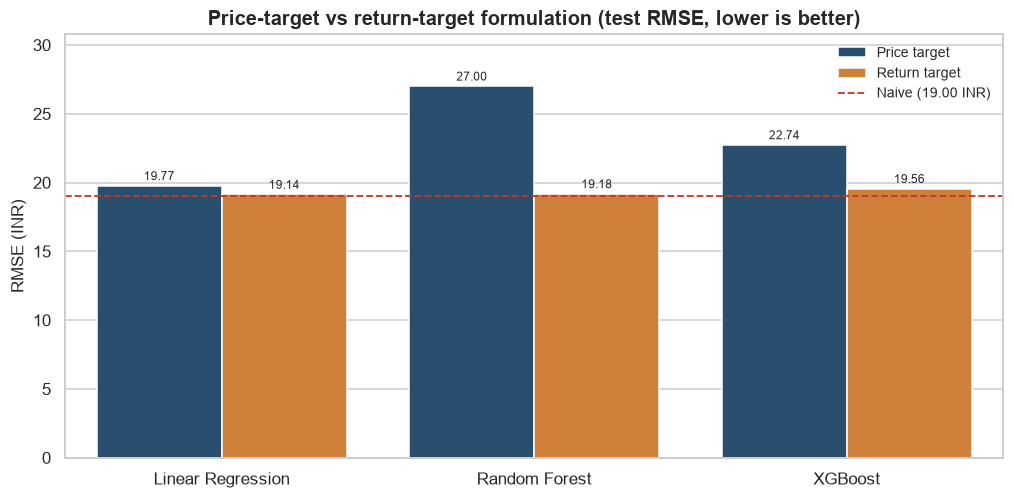

Formulation        Price target  Return target
Model                                         
Linear Regression         19.77          19.14
Random Forest             27.00          19.18
XGBoost                   22.74          19.56


In [25]:
# --- 8.2 Price-target vs return-target RMSE --------------------------------
base_models = ["Linear Regression", "Random Forest", "XGBoost"]
formulation_rows = []
for base in base_models:
    formulation_rows.append(
        {"Model": base, "Formulation": "Price target", "RMSE": results.loc[base, "RMSE"]}
    )
    formulation_rows.append(
        {"Model": base, "Formulation": "Return target", "RMSE": results.loc[f"{base} (return target)", "RMSE"]}
    )
formulation_df = pd.DataFrame(formulation_rows)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=formulation_df, x="Model", y="RMSE", hue="Formulation",
    palette=["#1f4e79", "#e67e22"], ax=ax,
)
ax.axhline(naive_rmse, color="#c0392b", ls="--", lw=1.2, label=f"Naive ({naive_rmse:,.2f} INR)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Price-target vs return-target formulation (test RMSE, lower is better)")
ax.set_ylabel("RMSE (INR)")
ax.set_xlabel("")
ax.legend(frameon=False, fontsize=9)
ax.margins(y=0.14)
save_fig(fig, "fig11_price_vs_return_rmse.png")
plt.show()

print(formulation_df.pivot(index="Model", columns="Formulation", values="RMSE").round(2).to_string())

### Direction classification

The classification target is `1` if the next-day return is strictly positive (UP) and `0` otherwise (DOWN;
the handful of exactly-flat days fall into DOWN). Three classifiers are trained on the same features and split:
Logistic Regression (standardised inputs), Random Forest and XGBoost. They are compared with a
**majority-class baseline** (`DummyClassifier(strategy="most_frequent")`): always predicting the training set's
dominant class. Accuracy alone is misleading with this baseline, so precision, recall and F1 for the UP class are
reported alongside, plus the confusion matrices.

No hyperparameter search is run for the classifiers — they use sensible fixed settings, because tuning a
direction classifier on 1,539 training days is itself a fast route to overfitting.

In [26]:
# ---------------------------------------------------------------------------
# 8.3 Direction classifiers: UP (1) vs DOWN (0)
# ---------------------------------------------------------------------------
y_dir_train = (r_train > 0).astype(int)
y_dir_test = (r_test > 0).astype(int)

classifier_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=SEED), X_train_scaled, X_test_scaled,
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=3,
                               random_state=SEED, n_jobs=1),
        X_train, X_test,
    ),
    "XGBoost": (
        XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=SEED, n_jobs=1, eval_metric="logloss"),
        X_train, X_test,
    ),
}

classifier_predictions = {}
for name, (model, X_fit, X_eval) in classifier_specs.items():
    model.fit(X_fit, y_dir_train)
    classifier_predictions[name] = model.predict(X_eval)

# Majority-class baseline, fitted on the training labels only.
majority_model = DummyClassifier(strategy="most_frequent").fit(X_train, y_dir_train)
classifier_predictions["Majority class baseline"] = majority_model.predict(X_test)

classifier_rows = []
for name, pred in classifier_predictions.items():
    classifier_rows.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_dir_test, pred) * 100,
        "Precision (%)": precision_score(y_dir_test, pred, zero_division=0) * 100,
        "Recall (%)": recall_score(y_dir_test, pred, zero_division=0) * 100,
        "F1 (%)": f1_score(y_dir_test, pred, zero_division=0) * 100,
    })

classifier_results = (
    pd.DataFrame(classifier_rows).set_index("Model").sort_values("Accuracy (%)", ascending=False)
)
classifier_results.round(2).to_csv(OUT_DIR / "classification_comparison.csv")

print(f"Train up-day share: {y_dir_train.mean() * 100:.1f}% | "
      f"Test up-day share: {y_dir_test.mean() * 100:.1f}%")
print("(precision / recall / F1 are for the UP class; the baseline always predicts the training majority class)")
display(classifier_results.round(2))

Train up-day share: 51.4% | Test up-day share: 49.6%
(precision / recall / F1 are for the UP class; the baseline always predicts the training majority class)


,Accuracy (%),Precision (%),Recall (%),F1 (%)
Model,,,,
Random Forest,51.69,51.40,48.17,49.73
Logistic Regression,50.91,50.29,91.62,64.94
XGBoost,50.13,49.62,34.55,40.74
Majority class baseline,49.61,49.61,100.00,66.32


Saved figure -> outputs\figures\fig12_confusion_matrices.png


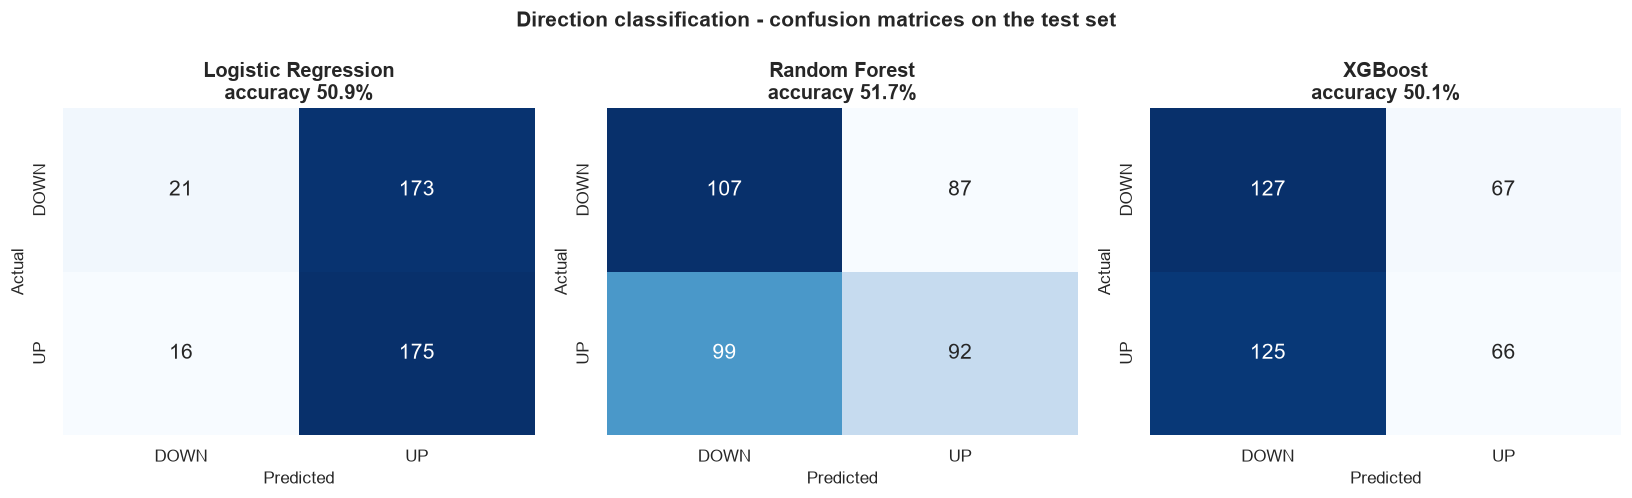

In [27]:
# --- 8.4 Confusion matrices ------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, classifier_specs):
    cm = confusion_matrix(y_dir_test, classifier_predictions[name], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"], annot_kws={"size": 14},
    )
    acc = accuracy_score(y_dir_test, classifier_predictions[name]) * 100
    ax.set_title(f"{name}\naccuracy {acc:.1f}%")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

fig.suptitle("Direction classification - confusion matrices on the test set", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig12_confusion_matrices.png")
plt.show()

Saved figure -> outputs\figures\fig13_classifier_comparison.png


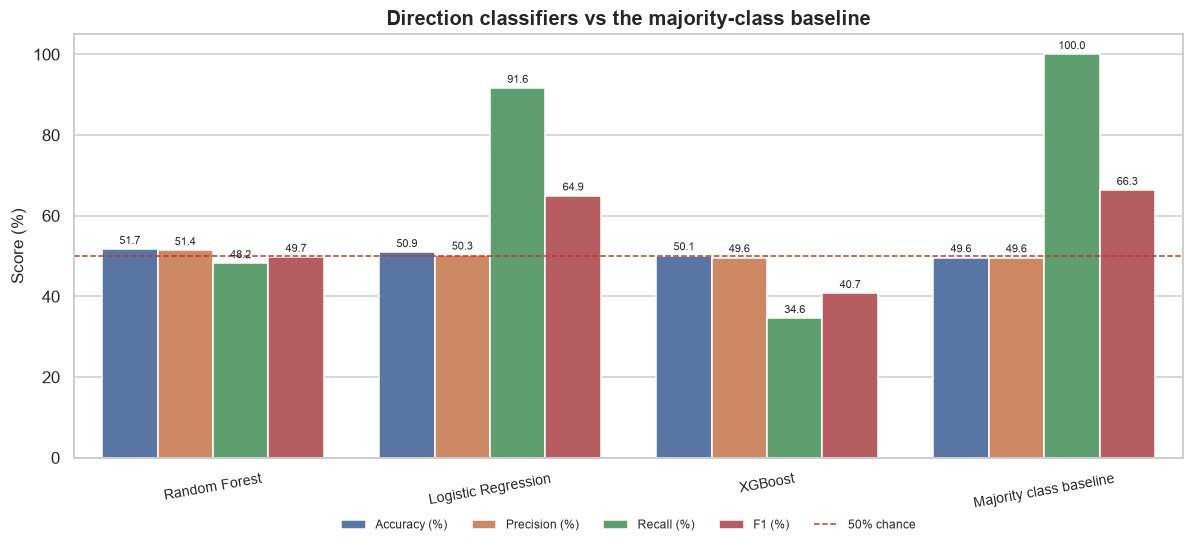

                         Accuracy (%)  Precision (%)  Recall (%)  F1 (%)
Model                                                                   
Random Forest                   51.69          51.40       48.17   49.73
Logistic Regression             50.91          50.29       91.62   64.94
XGBoost                         50.13          49.62       34.55   40.74
Majority class baseline         49.61          49.61      100.00   66.32


In [28]:
# --- 8.5 Classifier comparison ---------------------------------------------
metric_cols = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 (%)"]
chart_df = classifier_results.reset_index().melt(
    id_vars="Model", value_vars=metric_cols, var_name="Metric", value_name="Score (%)"
)

fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=chart_df, x="Model", y="Score (%)", hue="Metric", ax=ax)
ax.axhline(50, color="#c0392b", ls="--", lw=1, label="50% chance")
ax.set_title("Direction classifiers vs the majority-class baseline")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=10, labelsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=7, padding=2)
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.margins(y=0.12)
save_fig(fig, "fig13_classifier_comparison.png")
plt.show()

print(classifier_results.round(2).to_string())

**What the reformulation showed**

- **Return targets help the tree models a lot.** Random Forest drops from 27.00 to 19.18 INR RMSE and XGBoost
  from 22.74 to 19.56; the non-stationary price level was indeed inflating their errors. Linear Regression
  improves from 19.77 to 19.14 INR and becomes the **best fitted model** in the project.
- **The naive forecast is still the overall winner**: 19.00 INR RMSE and 13.53 INR MAE beat every fitted model.
  The best fitted model is 0.71% worse on RMSE and 2.6% worse on MAE than repeating today's close.
- **Direction classification is at chance.** Random Forest is the most accurate classifier at 51.7%, only
  2.1 percentage points above the majority-class baseline (49.6%) and well inside the ≈2.5 pp binomial
  standard error for 385 test days. Logistic Regression reaches 50.9% by predicting UP on 348 of 385 days
  (recall 91.6%, precision 50.3%); XGBoost is at 50.1%. The baseline's high F1 (66.3%) is an artefact of always
  predicting the training majority class, not evidence of skill.
- Overall: changing the target and the task did not create an exploitable edge on this stock and period.
  The honest verdict is carried into the conclusion (section 10); the main caveat is sample size: one 385-day
  test window cannot distinguish a 51.7% hit rate from a 50% coin flip (binomial standard error ≈ 2.5 pp).

## 9. Persisting the best fitted model and predicting tomorrow

The **best fitted model** is saved to `models/` together with everything needed to reproduce its input:
the feature list, the fitted scaler, the sequence window (for the LSTM) and its test metrics. The naive baseline
is the overall winner on RMSE and MAE, but it is a rule rather than a fitted model, so the deployment artifact is
the best *fitted* model. The LSTM is stored in Keras' native `.keras` format and referenced from the joblib
bundle, because Keras models do not pickle cleanly.

`predict_next_day()` reloads the bundle from disk, rebuilds features from the latest row of `data/stock.csv`
and returns tomorrow's forecast. It deliberately re-reads the CSV so it works in a fresh Python process.
By default it returns the predicted price (a `float`); pass `return_details=True` for the as-of date, the last
close and the expected percentage move. If the saved model was trained on returns, the bundle records that and
the function converts the predicted return back to a price.

In [29]:
# ---------------------------------------------------------------------------
# Save the best fitted model
# ---------------------------------------------------------------------------
def save_best_model(name: str, model, filepath: Path = MODEL_DIR / "best_model.joblib") -> Path:
    """Persist a model plus preprocessing metadata to a joblib bundle."""
    bundle = {
        "model_name": name,
        "features": FEATURE_COLS,
        "scaler": scaler,
        "y_scaler": y_scaler,
        "scaled_input": name.startswith("Linear Regression") or name.startswith("LSTM"),
        "target_type": "return" if name.endswith("(return target)") else "price",
        "window": WINDOW if name.startswith("LSTM") else None,
        "target": ("next trading day % return (converted to Close in INR)"
                   if name.endswith("(return target)") else "next trading day Close (INR)"),
        "ticker": TICKER,
        "trained_until": str(train_df["Date"].max().date()),
        "test_metrics": results.loc[name].round(4).to_dict(),
        "seed": SEED,
        "keras_path": None,
        "model": model,
    }

    if name.startswith("LSTM"):
        keras_path = MODEL_DIR / "lstm_model.keras"
        model.save(keras_path)
        bundle["model"] = None
        bundle["keras_path"] = str(keras_path)

    joblib.dump(bundle, filepath)
    return filepath


best_model_path = save_best_model(best_model_name, models[best_model_name])
print(f"Saved {best_model_name} -> {best_model_path.relative_to(PROJECT_ROOT)}")
print(f"Bundle contents: model/scaler/features/window/metrics (seed {SEED})")
print(f"Artifacts in models/: {[p.name for p in MODEL_DIR.iterdir() if p.is_file()]}")

Saved Linear Regression (return target) -> models\best_model.joblib
Bundle contents: model/scaler/features/window/metrics (seed 42)
Artifacts in models/: ['best_model.joblib']


In [30]:
# ---------------------------------------------------------------------------
# predict_next_day(): score tomorrow's close from the latest CSV row
# ---------------------------------------------------------------------------
def predict_next_day(csv_path: Path = DATA_PATH,
                     bundle_path: Path = MODEL_DIR / "best_model.joblib",
                     return_details: bool = False) -> float | dict:
    """Return tomorrow's predicted close using the persisted best fitted model.

    Reloads the model bundle from disk, rebuilds leakage-free features from
    ``csv_path`` and scores the most recent completed trading day.

    Parameters
    ----------
    csv_path : path to the OHLCV history (needs the most recent trading day).
    bundle_path : joblib bundle written by ``save_best_model``.
    return_details : if True, return a dict with the prediction and context;
                     otherwise return only the predicted close in INR.
    """
    bundle = joblib.load(bundle_path)
    raw = (
        pd.read_csv(csv_path, parse_dates=["Date"])
        .sort_values("Date")
        .drop_duplicates("Date")
        .reset_index(drop=True)
    )
    features = build_features(raw).dropna(subset=bundle["features"]).reset_index(drop=True)
    if features.empty:
        raise ValueError("Not enough history to build the required features.")

    last_row = features.iloc[[-1]]
    last_close = float(last_row["Close"].iloc[0])

    if bundle["model_name"].startswith("LSTM"):
        if not TF_AVAILABLE:
            raise RuntimeError("This bundle holds an LSTM and needs TensorFlow to load.")
        model = keras.models.load_model(bundle["keras_path"])
        window = int(bundle["window"])
        scaled_history = bundle["scaler"].transform(features[bundle["features"]].to_numpy(dtype=float))
        if len(scaled_history) < window:
            raise ValueError(f"Need at least {window} rows of history, got {len(scaled_history)}.")
        sequence = scaled_history[-window:][np.newaxis, :, :]
        prediction_scaled = model.predict(sequence, verbose=0).ravel()
        prediction = float(bundle["y_scaler"].inverse_transform(prediction_scaled.reshape(-1, 1)).ravel()[0])
    else:
        X_last = last_row[bundle["features"]].to_numpy(dtype=float)
        if bundle["scaled_input"]:
            X_last = bundle["scaler"].transform(X_last)
        prediction = float(bundle["model"].predict(X_last)[0])

    # A return-target bundle predicts a fraction; convert it back to a price.
    if bundle.get("target_type", "price") == "return":
        prediction = last_close * (1.0 + prediction)

    details = {
        "model": bundle["model_name"],
        "as_of": pd.Timestamp(raw["Date"].iloc[-1]).date().isoformat(),
        "last_close": round(last_close, 2),
        "predicted_next_close": round(prediction, 2),
        "predicted_change_pct": round(100 * (prediction - last_close) / last_close, 2),
    }
    return details if return_details else details["predicted_next_close"]


# The plain call returns just the price; ask for details for the printed summary.
tomorrow_price = predict_next_day()
tomorrow = predict_next_day(return_details=True)
print(json.dumps(tomorrow, indent=2))
print(f"\nTomorrow's predicted close: {tomorrow_price:,.2f} INR")
print("Check: the bundle on disk was reloaded, so this is the same prediction a")
print("standalone script would produce from the saved artifacts.")

{
  "model": "Linear Regression (return target)",
  "as_of": "2026-11-11",
  "last_close": 1337.1,
  "predicted_next_close": 1338.09,
  "predicted_change_pct": 0.07
}

Tomorrow's predicted close: 1,338.09 INR
Check: the bundle on disk was reloaded, so this is the same prediction a
standalone script would produce from the saved artifacts.


## 10. Conclusion

### Overall winner and best fitted model

**The naive forecast is the overall winner on both RMSE and MAE.** Repeating today's close gives 19.00 INR RMSE
and 13.53 INR MAE, and no fitted model — in either formulation — improves on either metric.

**Linear Regression is the best fitted model.** Its return-target variant is the strongest fitted model at
19.14 INR RMSE / 13.89 INR MAE / 1.01% MAPE (R² 0.9593), only 0.7% worse on RMSE and 2.6% worse on MAE than the
naive forecast. The price-target Linear Regression is the best price-target model at 19.77 INR RMSE.

| Model | RMSE (INR) | MAE (INR) | MAPE (%) | R² | Directional accuracy (%) |
|---|---:|---:|---:|---:|---:|
| **Naive (tomorrow = today)** | **19.00** | **13.53** | **0.99** | **0.9599** | **N/A** |
| Linear Regression (return target) — best fitted | 19.14 | 13.89 | 1.01 | 0.9593 | 46.5 |
| Random Forest (return target) | 19.18 | 13.74 | 1.00 | 0.9591 | 48.8 |
| XGBoost (return target) | 19.56 | 14.08 | 1.02 | 0.9575 | 50.1 |
| Linear Regression (price target) | 19.77 | 14.23 | 1.04 | 0.9566 | 49.9 |
| XGBoost (price target) | 22.74 | 17.05 | 1.24 | 0.9425 | 50.4 |
| Random Forest (price target) | 27.00 | 20.68 | 1.50 | 0.9189 | 47.0 |
| LSTM (60-day window) | 40.81 | 31.56 | 2.26 | 0.8148 | 48.3 |

The naive forecast's directional accuracy is **N/A**, not 0%: it always predicts zero change, so it never makes
an up/down call that could be right or wrong.

### What the return formulation and classifiers changed

- **Return targets rescued the tree models**: Random Forest improved from 27.00 to 19.18 INR RMSE and XGBoost
  from 22.74 to 19.56, because the price level (which trees cannot extrapolate) was removed from the target.
  Linear Regression improved from 19.77 to 19.14 and became the best fitted model. On the return scale the three
  models score 0.01426, 0.01431 and 0.01459 RMSE (about 1.43%–1.46% of price per day).
- **The naive forecast still wins**: the gap is small (0.71% RMSE, 2.6% MAE), but it points the wrong way, and it
  persists after changing the target.
- **Direction classification shows no edge.** Random Forest is the most accurate at 51.7%, against a 49.6%
  majority-class baseline (+2.1 pp); Logistic Regression is 50.9% and XGBoost 50.1%. The binomial standard error
  on 385 days is ≈2.5 pp, so none of these is distinguishable from chance. Logistic Regression's high recall
  (91.6%) comes from predicting UP on 348 of 385 days, and the baseline's F1 of 66.3% is an artefact of always
  predicting the training majority class.
- **R² is not evidence of skill.** Every price-level model scores 0.81–0.96 because the price level is
  persistent; repeating today's close already reaches R² 0.96.

The honest verdict: on this stock and period, **technical-indicator ML does not beat a random walk for next-day
price prediction, in price or return form, and does not reliably predict direction.** That is a legitimate
result. This is consistent with the random-walk / weak-form efficient market view, although one stock and one
test window cannot prove it. It is more useful than an inflated claim of predictive power.

### Limitations

- **Markets are noisy.** Even a good next-day point forecast is dominated by price persistence; small RMSE
  differences from the naive forecast do not imply a tradable edge.
- **Information ceiling.** Every feature is a function of past price and volume. Once `Lag_1` is in the model,
  RSI/MACD/Bollinger features add little unique information, which is why the extra complexity did not pay off.
- **No news, sentiment or fundamentals.** Earnings surprises, index flows, crude prices, currency moves and
  macro events are invisible to the model.
- **Small, single-asset sample.** Eight years of one Indian large-cap and one 385-day test window is a small
  sample; results may not transfer to other tickers, regimes or split dates. For direction classification the
  binomial standard error alone (≈2.5 pp) is larger than any edge observed.
- **Classification base rate.** With roughly balanced classes, a majority-class baseline is a strong benchmark,
  and precision/recall trade-offs can look impressive while adding no information.
- **Evaluation ignores costs.** No brokerage, taxes, slippage or position sizing; a price forecast is not a
  strategy. A 50% directional hit rate would lose money after costs.
- **Residual risk of overfitting.** Hyperparameters were tuned with time-series CV, but repeated experiments on
  the same test window still leak some information through model selection.
- **Past performance does not guarantee future results.** This is a project for the Corizo Machine Learning program, not investment advice.

**Future work.** Multivariate inputs (index, sector, crude, USD/INR), sentiment from news and earnings calls,
calibrated probabilities and conformal prediction intervals, walk-forward/rolling retraining across many stocks,
and transaction-cost-aware backtesting. The return and direction formulations have now been tested; the next
step is richer information (cross-sectional and macro features) rather than more capacity for models that are
already at the information ceiling.

In [31]:
# ---------------------------------------------------------------------------
# Final summary (printed so a headless run ends with the numbers)
# ---------------------------------------------------------------------------
best_row = results.loc[best_model_name]
naive_row = results.loc["Naive (tomorrow = today)"]

print("=" * 84)
print("STOCK PRICE PREDICTION - FINAL TEST-SET SUMMARY")
print("=" * 84)
print(f"Ticker / period : {TICKER} | test {test_df['Date'].min():%Y-%m-%d} -> {test_df['Date'].max():%Y-%m-%d}")
print(f"Test rows       : {len(test_df):,}")
print("(directional accuracy is N/A for the naive forecast: it predicts no change)")
print()
print(format_results_table(results).to_string())
print()
print(f"Best fitted model : {best_model_name}")
print(f"  RMSE {best_row['RMSE']:,.2f} INR | MAE {best_row['MAE']:,.2f} INR | "
      f"MAPE {best_row['MAPE (%)']:.2f}% | R2 {best_row['R2']:.4f} | "
      f"direction {best_row['Directional Acc (%)']:.1f}%")
print(f"Naive baseline    : RMSE {naive_row['RMSE']:,.2f} INR | MAE {naive_row['MAE']:,.2f} INR | "
      f"MAPE {naive_row['MAPE (%)']:.2f}% | R2 {naive_row['R2']:.4f} | direction N/A")
rmse_delta = (naive_row["RMSE"] - best_row["RMSE"]) / naive_row["RMSE"] * 100
print()
if naive_row["RMSE"] <= results["RMSE"].min() and naive_row["MAE"] <= results["MAE"].min():
    print("Verdict            : the naive baseline is the OVERALL WINNER on both RMSE and MAE.")
else:
    print("Verdict            : a fitted model beats the naive baseline on RMSE and/or MAE.")
print(f"                     {best_model_name} is the best fitted model "
      f"({abs(rmse_delta):.2f}% {'worse' if rmse_delta < 0 else 'better'} RMSE than naive).")
print(f"Artifacts          : {best_model_path.relative_to(PROJECT_ROOT)}, "
      f"outputs/model_comparison.csv, {len(list(FIG_DIR.glob('*.png')))} figures")
print("=" * 84)

STOCK PRICE PREDICTION - FINAL TEST-SET SUMMARY
Ticker / period : RELIANCE.NS | test 2025-04-23 -> 2026-11-09
Test rows       : 385
(directional accuracy is N/A for the naive forecast: it predicts no change)

                                    RMSE    MAE  MAPE (%)    R2 Directional Acc (%)
Model                                                                              
Naive (tomorrow = today)           19.00  13.53      0.99  0.96                 N/A
Linear Regression (return target)  19.14  13.89      1.01  0.96               46.49
Random Forest (return target)      19.18  13.74      1.00  0.96               48.83
XGBoost (return target)            19.56  14.08      1.02  0.96               50.13
Linear Regression                  19.77  14.23      1.04  0.96               49.87
XGBoost                            22.74  17.05      1.24  0.94               50.39
Random Forest                      27.00  20.68      1.50  0.92               47.01
LSTM (60-day window)               